# Binary Classification of Driver Fatality Outcomes Using Logistic Regression, Decision Trees, Random Forests, and XGBoost

**Question:** given a driver and the crash they were in, can we predict whether the driver was killed?

**Data:** NHTSA Fatality Analysis Reporting System (FARS), person-level table for 2015, 30 columns exported from the Google BigQuery public dataset `nhtsa_traffic_fatalities`. The notebook expects the export as `fars data.csv` in the same folder. Code meanings are listed in `fars_code_reference.txt`.

**Contents**

1. Load and inspect
2. Clean (unknown codes, labels, types)
3. Derived columns
4. Exploratory analysis: all people in fatal crashes
5. Exploratory analysis: crash level
6. Alcohol
7. Drugs
8. Correlation with driver fatality
9. Vehicle class and restraint / helmet use
10. Model building, tuning, evaluation and saved models

Run the notebook top to bottom. Sections 4 to 9 are exploratory and only section 10 trains models.

## 1. Load and inspect

In [1]:
import calendar
import os
import pickle
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, loguniform
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

# the parallel searches in section 10 raise a harmless sklearn warning for every worker
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
pd.set_option("display.max_columns", None)

# Read everything as text first so codes such as "07" are not changed by type guessing.
df = pd.read_csv("data//fars data.csv", dtype=str)
df.head(10)

,consecutive_number,person_number,state_number,county,timestamp_of_crash,land_use,functional_system,number_of_motor_vehicles_in_transport_mvit,first_harmful_event,manner_of_collision,school_bus_related,vehicle_make,body_type,rollover,fire_occurrence,age,sex,person_type,injury_severity,restraint_system_helmet_use,air_bag_deployed,ejection,police_reported_alcohol_involvement,alcohol_test_status1,alcohol_test_status3,police_reported_drug_involvement,drug_test_status,drug_test_type4,drug_test_type5,drug_test_type6
0,390301,1,39,35,2015-05-06 00:25:00 UTC,8,98,1,33,0,No,49,4,No Rollover,No or Not Reported,23,Male,1,4,7,20,0,Yes (Alcohol Involved),Test Given,174,No (Drugs Not Involved),Test Given,600,996,0
1,240301,1,24,27,2015-06-14 15:55:00 UTC,8,98,1,39,0,No,55,4,No Rollover,No or Not Reported,83,Female,1,4,7,8,0,No (Alcohol Not Involved),Test Given,0,No (Drugs Not Involved),Test Given,239,996,0
2,390999,1,39,7,2015-12-13 01:11:00 UTC,9,7,1,42,0,No,6,9,"Rollover, Tripped by Object/Vehicle",No or Not Reported,21,Male,1,4,7,1,1,Yes (Alcohol Involved),Test Given,159,Yes (Drugs Involved),Test Given,695,996,0
3,270285,1,27,165,2015-10-06 11:22:00 UTC,1,3,2,12,1,No,12,21,No Rollover,No or Not Reported,29,Female,1,4,3,1,0,Unknown (Police Reported),Test Given,0,Unknown (Police Reported),Test Given,401,996,0
4,170522,1,17,143,2015-08-17 15:50:00 UTC,1,5,2,12,2,No,20,31,No Rollover,No or Not Reported,60,Male,1,4,7,8,0,Unknown (Police Reported),Test Given,0,Yes (Drugs Involved),Test Given,402,407,996
5,380037,1,38,93,2015-05-26 10:18:00 UTC,1,4,1,1,0,No,82,66,"Rollover, Tripped by Object/Vehicle",No or Not Reported,58,Male,1,4,3,20,0,Unknown (Police Reported),Test Given,0,Unknown (Police Reported),Test Given,300,996,0
6,290022,1,29,71,2015-01-15 17:11:00 UTC,1,3,3,12,6,No,12,4,No Rollover,No or Not Reported,50,Male,1,4,3,20,0,Yes (Alcohol Involved),Test Given,62,Not Reported,Test Given,155,157,177
7,380007,1,38,53,2015-01-28 20:28:00 UTC,1,3,2,12,6,No,20,4,No Rollover,No or Not Reported,18,Male,1,4,3,1,0,No (Alcohol Not Involved),Test Given,14,No (Drugs Not Involved),Test Given,695,996,0
8,530369,1,53,63,2015-09-19 16:55:00 UTC,1,3,3,12,6,No,48,6,No Rollover,No or Not Reported,44,Female,1,4,3,1,0,Yes (Alcohol Involved),Test Given,300,Not Reported,Test Given,605,695,0
9,170152,1,17,55,2015-02-12 22:40:00 UTC,1,4,2,12,6,No,2,14,No Rollover,No or Not Reported,23,Male,1,4,3,0,0,Unknown (Police Reported),Test Given,0,Yes (Drugs Involved),Test Given,605,695,0


In [2]:
df.dtypes

consecutive_number                            object
person_number                                 object
state_number                                  object
county                                        object
timestamp_of_crash                            object
land_use                                      object
functional_system                             object
number_of_motor_vehicles_in_transport_mvit    object
first_harmful_event                           object
manner_of_collision                           object
school_bus_related                            object
vehicle_make                                  object
body_type                                     object
rollover                                      object
fire_occurrence                               object
age                                           object
sex                                           object
person_type                                   object
injury_severity                               

In [3]:
print(df.shape)
print(df.columns.tolist())
print(df.isna().mean().sort_values(ascending=False).head(15))
print(df["injury_severity"].value_counts(dropna=False))
print("fully duplicated rows:", df.duplicated().sum())

(81620, 30)
['consecutive_number', 'person_number', 'state_number', 'county', 'timestamp_of_crash', 'land_use', 'functional_system', 'number_of_motor_vehicles_in_transport_mvit', 'first_harmful_event', 'manner_of_collision', 'school_bus_related', 'vehicle_make', 'body_type', 'rollover', 'fire_occurrence', 'age', 'sex', 'person_type', 'injury_severity', 'restraint_system_helmet_use', 'air_bag_deployed', 'ejection', 'police_reported_alcohol_involvement', 'alcohol_test_status1', 'alcohol_test_status3', 'police_reported_drug_involvement', 'drug_test_status', 'drug_test_type4', 'drug_test_type5', 'drug_test_type6']
rollover                                      0.086547
body_type                                     0.086547
vehicle_make                                  0.086547
fire_occurrence                               0.086547
consecutive_number                            0.000000
state_number                                  0.000000
land_use                                      0.0000

**Duplicate rows.** The 21 fully duplicated rows are kept. The 30-column extract has no vehicle-number column, so two people with the same person number in different vehicles of one crash can legitimately look identical.

## 2. Clean

FARS stores "not reported", "unknown" and "not applicable" as ordinary codes (8, 9, 98, 99, ...). They are set to missing here so that no statistic or model treats them as real values.

In [4]:
# trim stray whitespace and turn empty strings into missing values
df = df.apply(lambda s: s.str.strip())
df = df.replace("", pd.NA)

In [5]:
# columns stored as numeric codes
code_cols = ["state_number", "county", "land_use", "functional_system",
             "first_harmful_event", "manner_of_collision", "vehicle_make",
             "body_type", "person_type", "injury_severity",
             "restraint_system_helmet_use", "air_bag_deployed", "ejection",
             "drug_test_type4", "drug_test_type5", "drug_test_type6"]

for c in code_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")


print(df.dtypes.head(30))

consecutive_number                            object
person_number                                 object
state_number                                   Int64
county                                         Int64
timestamp_of_crash                            object
land_use                                       Int64
functional_system                              Int64
number_of_motor_vehicles_in_transport_mvit    object
first_harmful_event                            Int64
manner_of_collision                            Int64
school_bus_related                            object
vehicle_make                                   Int64
body_type                                      Int64
rollover                                      object
fire_occurrence                               object
age                                           object
sex                                           object
person_type                                    Int64
injury_severity                               

In [6]:
# numeric columns: codes meaning not applicable / not reported / unknown (see fars_code_reference.txt)
unknown_codes = {
    "county": [0, 997, 998, 999],
    "land_use": [6, 8, 9],
    "functional_system": [96, 98, 99],
    "first_harmful_event": [99],
    "manner_of_collision": [98, 99],
    "injury_severity": [5, 6, 9],
    "restraint_system_helmet_use": [0, 29, 98, 99],
    "air_bag_deployed": [0, 98, 99],
    "ejection": [7, 8, 9],
}
for c, codes in unknown_codes.items():
    df[c] = df[c].mask(df[c].isin(codes))

In [7]:
# text columns: labels meaning not reported / unknown
missing_labels = {
    "sex": ["Not Reported", "Unknown"],
    "school_bus_related": ["Not Reported"],
    "police_reported_alcohol_involvement": ["Not Reported", "Unknown (Police Reported)"],
    "police_reported_drug_involvement": ["Not Reported", "Unknown (Police Reported)"],
    "alcohol_test_status1": ["Not Reported", "Unknown if Tested"],
    "drug_test_status": ["Not Reported", "Unknown if Tested"],
}
for c, bad in missing_labels.items():
    df[c] = df[c].replace(bad, pd.NA)

In [8]:
age = pd.to_numeric(df["age"], errors="coerce")
df["age"] = age.mask(age >= 998).astype("Int64")

df["number_of_motor_vehicles_in_transport_mvit"] = pd.to_numeric(
    df["number_of_motor_vehicles_in_transport_mvit"], errors="coerce").astype("Int64")

# alcohol_test_status3 holds the BAC result in thousandths of g/dL (174 = 0.174)
bac = pd.to_numeric(df["alcohol_test_status3"], errors="coerce")
df["bac"] = bac.where(bac <= 940) / 1000      # 995-999 become missing
df = df.drop(columns="alcohol_test_status3")

In [9]:
# Hours and weekdays are used as stored. The BigQuery timestamp carries a UTC label, but FARS records
# the local time of the crash, so crash_hour is local clock time.
df["timestamp_of_crash"] = pd.to_datetime(df["timestamp_of_crash"], utc=True)
df["crash_hour"] = df["timestamp_of_crash"].dt.hour
df["crash_weekday"] = df["timestamp_of_crash"].dt.day_name()
df["crash_month"] = df["timestamp_of_crash"].dt.month
df["is_weekend"] = df["timestamp_of_crash"].dt.dayofweek >= 5

## 3. Derived columns

`death_per_crash` is built from the outcome, so it is used for exploration only and is never a model feature.

In [10]:
kabco = {0: "O", 1: "C", 2: "B", 3: "A", 4: "K"}
df["injury_level"] = pd.Categorical(
    df["injury_severity"].map(kabco),
    categories=["O", "C", "B", "A", "K"], ordered=True)

ej = {0: "Not ejected", 2: "Partially ejected", 1: "Totally ejected", 3: "Ejected, unknown degree"}
unmapped = sorted(set(df["ejection"].dropna()) - set(ej))
print("unmapped ejection codes:", unmapped)
assert not unmapped
df["ejection_level"] = pd.Categorical(
    df["ejection"].map(ej),
    categories=["Not ejected", "Partially ejected", "Ejected, unknown degree", "Totally ejected"], ordered=True)

df["functional_system_ord"] = pd.Categorical(
    df["functional_system"], categories=[1, 2, 3, 4, 5, 6, 7], ordered=True)

unmapped ejection codes: []


In [11]:
# 1 = tested negative; 100-996 and 998 = a drug was found; anything else leaves the result missing
drug_slots = df[["drug_test_type4", "drug_test_type5", "drug_test_type6"]]
positive = (((drug_slots >= 100) & (drug_slots <= 996)) | (drug_slots == 998)).any(axis=1)
negative = (df["drug_test_type4"] == 1).fillna(False)
df["any_drug_found"] = np.where(positive, 1.0, np.where(negative, 0.0, np.nan))

In [12]:
died = (df["injury_severity"] == 4).fillna(False)
df["deaths_in_crash"] = died.groupby(df["consecutive_number"]).transform("sum")
df["people_in_crash"] = df.groupby("consecutive_number")["consecutive_number"].transform("size")
df["death_per_crash"] = df["deaths_in_crash"] / df["people_in_crash"]

In [13]:
fhe_groups = {
    "Non-collision": [1, 2, 3, 4, 5, 6, 7, 16, 44, 51, 72],
    "Collision with vehicle": [12, 54, 55],
    "Object not fixed": [8, 9, 10, 11, 14, 15, 18, 45, 49, 73],
    "Fixed object": [17, 19, 20, 21, 23, 24, 25, 26, 30, 31, 32, 33, 34, 35,
                     38, 39, 40, 41, 42, 43, 46, 48, 50, 52, 53, 57, 58, 59],
}
lookup = {code: g for g, codes in fhe_groups.items() for code in codes}
df["first_event_group"] = df["first_harmful_event"].map(lookup)

In [14]:
def missing_report(df):
    m = df.isna().sum()
    out = pd.DataFrame({"missing": m, "pct": (m / len(df) * 100).round(1)})
    return out[out.missing > 0].sort_values("pct", ascending=False)

print(missing_report(df))

                                     missing   pct
any_drug_found                         56095  68.7
bac                                    50095  61.4
police_reported_drug_involvement       44682  54.7
police_reported_alcohol_involvement    39259  48.1
air_bag_deployed                       22220  27.2
ejection_level                         13560  16.6
ejection                               13560  16.6
restraint_system_helmet_use             7876   9.6
fire_occurrence                         7064   8.7
rollover                                7064   8.7
vehicle_make                            7064   8.7
body_type                               7064   8.7
drug_test_status                        4589   5.6
alcohol_test_status1                    4150   5.1
age                                     1738   2.1
sex                                     1437   1.8
injury_severity                         1049   1.3
injury_level                            1049   1.3
functional_system              

In [15]:
print(df["injury_severity"].value_counts(dropna=False).sort_index())
print(df["alcohol_test_status1"].value_counts(dropna=False))
print(pd.crosstab(df["alcohol_test_status1"], df["bac"].isna(), margins=True))
print(pd.crosstab(df["drug_test_status"], df["any_drug_found"].isna(), margins=True))

injury_severity
0       20050
1        7485
2        9117
3        8435
4       35484
<NA>     1049
Name: count, dtype: Int64
alcohol_test_status1
Test Not Given    44628
Test Given        32767
<NA>               4150
Test Refused         75
Name: count, dtype: int64
bac                   False   True    All
alcohol_test_status1                     
Test Given            31525   1242  32767
Test Not Given            0  44628  44628
Test Refused              0     75     75
All                   31525  45945  77470
any_drug_found    False   True    All
drug_test_status                     
Test Given        25525   1444  26969
Test Not Given        0  50021  50021
Test Refused          0     41     41
All               25525  51506  77031


## 4. Exploratory analysis: all people in fatal crashes

The analysis population is everyone whose injury outcome is known (KABCO codes 0 to 4). "Killed" is code 4. Injury codes 5, 6 and 9 were set to missing above and are left out.

In [16]:
known = df[df["injury_severity"].isin([0, 1, 2, 3, 4])].copy()
known["killed"] = known["injury_severity"] == 4
known["outcome"] = np.where(known["killed"], "Killed", "Survived")
known["month_name"] = known["crash_month"].map(lambda m: calendar.month_abbr[m])
month_order = list(calendar.month_abbr)[1:]   # Jan ... Dec

print(len(known))
print(known["outcome"].value_counts())
print(known["month_name"].value_counts().reindex(month_order))

80571
outcome
Survived    45087
Killed      35484
Name: count, dtype: int64
month_name
Jan    5835
Feb    4933
Mar    6048
Apr    6035
May    6960
Jun    6945
Jul    7634
Aug    7489
Sep    7063
Oct    7481
Nov    6982
Dec    7166
Name: count, dtype: int64


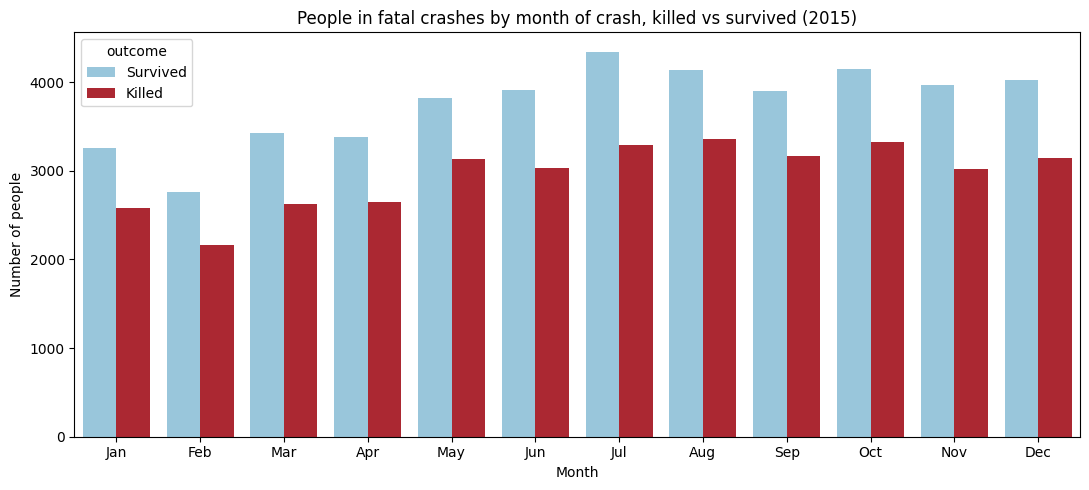

In [17]:
plt.figure(figsize=(11, 5))
ax = sns.countplot(data=known, x="month_name", hue="outcome",
                   order=month_order, hue_order=["Survived", "Killed"],
                   palette={"Survived": "#8ecae6", "Killed": "#c1121f"})
ax.set_title("People in fatal crashes by month of crash, killed vs survived (2015)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of people")
plt.tight_layout()
plt.show()

            people  killed  share_killed_%
month_name                                
Jan           5835    2577            44.2
Feb           4933    2168            43.9
Mar           6048    2625            43.4
Apr           6035    2652            43.9
May           6960    3136            45.1
Jun           6945    3035            43.7
Jul           7634    3288            43.1
Aug           7489    3354            44.8
Sep           7063    3163            44.8
Oct           7481    3328            44.5
Nov           6982    3016            43.2
Dec           7166    3142            43.8


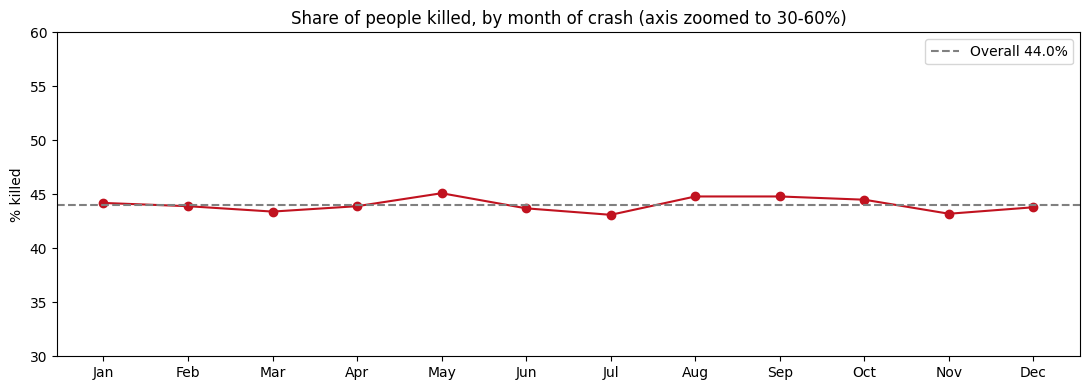

In [18]:
by_month = (known.groupby("month_name")["outcome"]
              .agg(people="size", killed=lambda s: (s == "Killed").sum()))
by_month["share_killed_%"] = (by_month["killed"] / by_month["people"] * 100).round(1)
by_month = by_month.reindex(month_order)
print(by_month)

overall = (known["outcome"] == "Killed").mean() * 100

plt.figure(figsize=(11, 4))
plt.plot(by_month.index, by_month["share_killed_%"], marker="o", color="#c1121f")
plt.axhline(overall, linestyle="--", color="grey", label=f"Overall {overall:.1f}%")
plt.ylim(30, 60)
plt.ylabel("% killed")
plt.title("Share of people killed, by month of crash (axis zoomed to 30-60%)")
plt.legend()
plt.tight_layout()
plt.show()

`death_per_crash` has the same value for everyone in a crash, so the averages below are weighted by people: crashes with more people count more.

In [19]:
monthly_death_rate = (
    known.groupby("month_name")["death_per_crash"]
    .mean()
    .reindex(month_order)
)

print(monthly_death_rate.round(3))

month_name
Jan    0.436
Feb    0.435
Mar    0.431
Apr    0.435
May    0.447
Jun    0.433
Jul    0.426
Aug    0.443
Sep    0.443
Oct     0.44
Nov    0.427
Dec    0.433
Name: death_per_crash, dtype: Float64


crash_hour
0     0.522
1     0.504
2     0.501
3     0.524
4     0.512
5     0.471
6     0.466
7     0.449
8     0.432
9     0.421
10    0.438
11    0.418
12      0.4
13    0.415
14      0.4
15    0.397
16    0.402
17    0.406
18     0.41
19    0.412
20    0.419
21    0.422
22    0.452
23    0.478
Name: death_per_crash, dtype: Float64


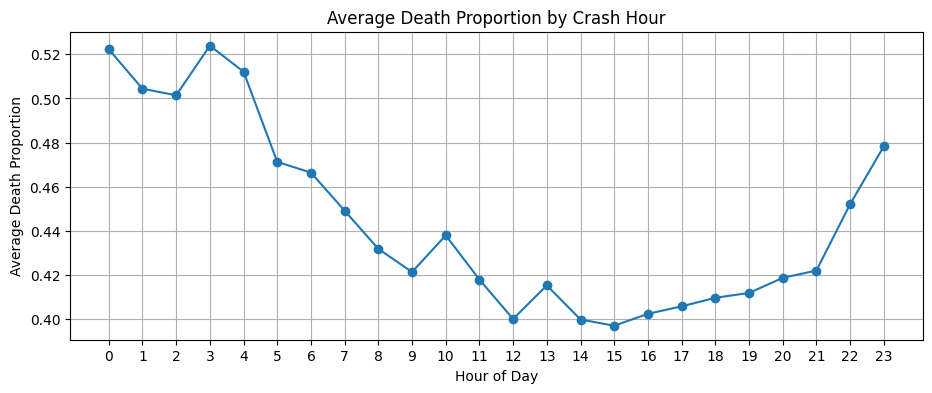

In [20]:
plt.figure(figsize=(11, 4))
hourly_death_rate = (
    known.groupby("crash_hour")["death_per_crash"]
    .mean()
)

print(hourly_death_rate.round(3))

hourly_death_rate.plot(kind="line", marker="o")
plt.title("Average Death Proportion by Crash Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Death Proportion")
plt.xticks(range(24))
plt.grid(True)
plt.show()

crash_hour
0     1656
1     1360
2     1326
3     1039
4      834
5     1067
6     1309
7     1245
8      976
9     1028
10    1122
11    1250
12    1342
13    1513
14    1655
15    1839
16    1822
17    1992
18    2046
19    1933
20    2004
21    1960
22    1701
23    1465
dtype: int64
total deaths: 35484


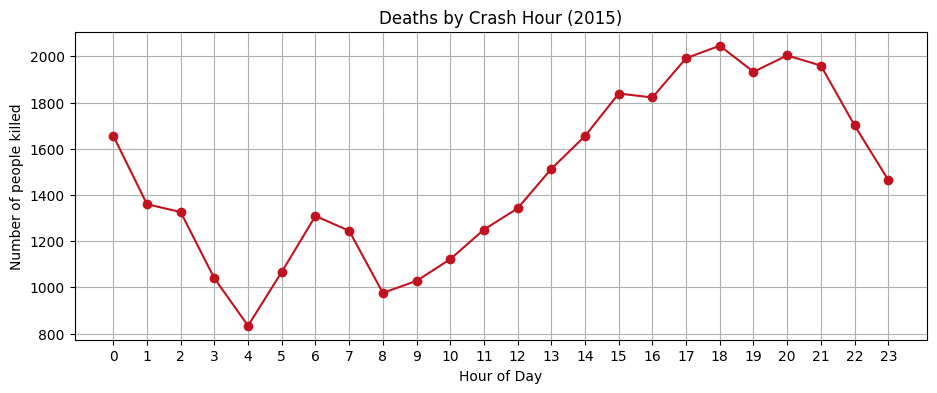

In [21]:
deaths_by_hour = known[known["outcome"] == "Killed"].groupby("crash_hour").size()

print(deaths_by_hour)
print("total deaths:", deaths_by_hour.sum())
assert deaths_by_hour.sum() == (df["injury_severity"] == 4).sum()

plt.figure(figsize=(11, 4))
deaths_by_hour.plot(kind="line", marker="o", color="#c1121f")
plt.title("Deaths by Crash Hour (2015)")
plt.xlabel("Hour of Day")
plt.ylabel("Number of people killed")
plt.xticks(range(24))
plt.grid(True)
plt.show()

In [22]:
age_labels = ["0-4", "5-14", "15-20", "21-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
known["age_group"] = pd.cut(known["age"], bins=[-1, 4, 14, 20, 29, 39, 49, 59, 69, 79, 120],
                            labels=age_labels)

print(f"people with known outcome: {len(known):,}")
print(f"overall share killed: {known['killed'].mean():.1%}")
print("age missing:", known["age"].isna().sum(), "| sex missing:", known["sex"].isna().sum())

people with known outcome: 80,571
overall share killed: 44.0%
age missing: 1121 | sex missing: 868


using 79,450 people
outcome    Survived  Killed  share_killed_%
age_group                                  
0-4            1622     379            18.9
5-14           3279     765            18.9
15-20          5803    3348            36.6
21-29          9040    7032            43.8
30-39          7043    5218            42.6
40-49          5938    4649            43.9
50-59          5589    5591            50.0
60-69          3314    3996            54.7
70-79          1678    2416            59.0
80+             740    2010            73.1


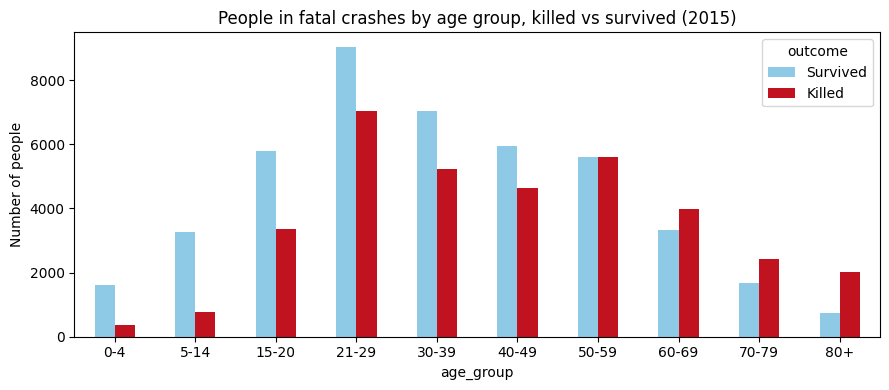

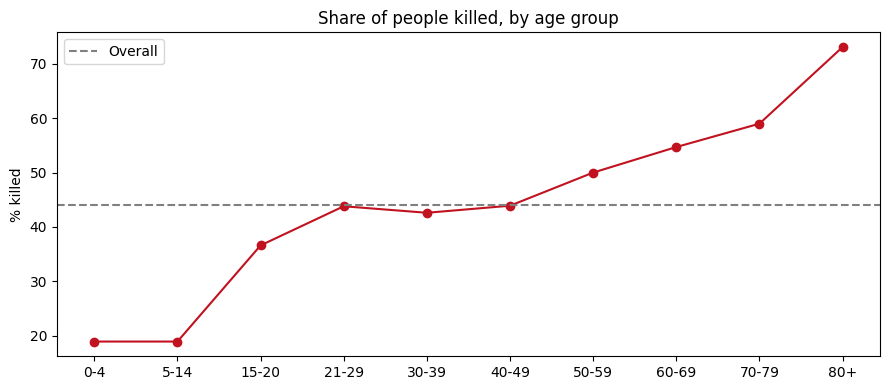

In [23]:
d = known[known["age_group"].notna()]
print(f"using {len(d):,} people")

counts = pd.crosstab(d["age_group"], d["outcome"])[["Survived", "Killed"]]
counts["share_killed_%"] = (counts["Killed"] / counts.sum(axis=1) * 100).round(1)
print(counts)

counts[["Survived", "Killed"]].plot(kind="bar", figsize=(9, 4), color=["#8ecae6", "#c1121f"])
plt.ylabel("Number of people")
plt.title("People in fatal crashes by age group, killed vs survived (2015)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(counts.index.astype(str), counts["share_killed_%"], marker="o", color="#c1121f")
plt.axhline(known["killed"].mean() * 100, linestyle="--", color="grey", label="Overall")
plt.ylabel("% killed")
plt.title("Share of people killed, by age group")
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
d = known[known["sex"].isin(["Male", "Female"])]
print(f"using {len(d):,} people")

s = d.groupby("sex")["killed"].agg(people="size", killed="sum", share="mean")
s["share"] = (s["share"] * 100).round(1)
s["share_of_all_people_%"] = (s["people"] / s["people"].sum() * 100).round(1)
print(s)

using 79,703 people
        people  killed  share  share_of_all_people_%
sex                                                 
Female   26795   10284   38.4                   33.6
Male     52908   25178   47.6                   66.4


                  people  share
age_group sex                  
0-4       Female     951   17.6
          Male      1040   20.3
5-14      Female    1959   16.7
          Male      2076   21.1
15-20     Female    3426   31.9
          Male      5719   39.4
21-29     Female    4860   35.5
          Male     11201   47.3
30-39     Female    3823   36.6
          Male      8433   45.3
40-49     Female    3179   38.7
          Male      7400   46.2
50-59     Female    3303   44.5
          Male      7853   52.5
60-69     Female    2380   46.8
          Male      4914   58.6
70-79     Female    1607   54.6
          Male      2483   61.9
80+       Female    1186   72.8
          Male      1563   73.3


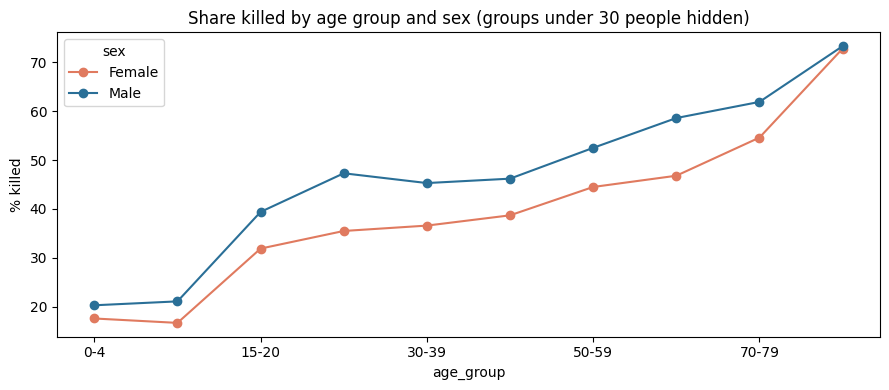

In [25]:
d = known[known["sex"].isin(["Male", "Female"]) & known["age_group"].notna()]
g = (d.groupby(["age_group", "sex"], observed=True)["killed"]
       .agg(people="size", share="mean"))
g["share"] = (g["share"] * 100).round(1)
print(g)

wide = g["share"].unstack()
people = g["people"].unstack()
wide = wide.where(people >= 30)

wide.plot(marker="o", figsize=(9, 4), color={"Male": "#2a6f97", "Female": "#e07a5f"})
plt.ylabel("% killed")
plt.title("Share killed by age group and sex (groups under 30 people hidden)")
plt.tight_layout()
plt.show()

using 80,571 people
                                        people  killed  share
person_label                                                 
Driver                                   48429   22350   46.2
Passenger                                24688    6504   26.3
Pedestrian                                5917    5494   92.9
Bicyclist                                  864     828   95.8
Occupant, vehicle not in-transport         283      32   11.3
Person on personal conveyance              174     160   92.0
Unknown occupant type                      116      74   63.8
Occupant of non-motor transport device      68      26   38.2
Person in/on building                       30      15   50.0
Other cyclist                                1       1  100.0
Unknown non-motorist                         1       0    0.0
                        people  killed  share
road_user                                    
In a motor vehicle       73516   28960   39.4
Not in a motor vehicle    7055    65

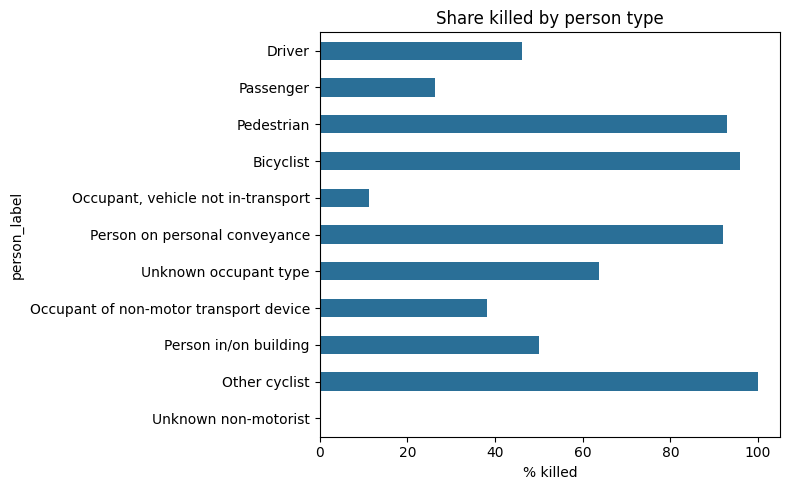

In [26]:
pt_labels = {1: "Driver", 2: "Passenger", 3: "Occupant, vehicle not in-transport",
             9: "Unknown occupant type", 4: "Occupant of non-motor transport device",
             5: "Pedestrian", 6: "Bicyclist", 7: "Other cyclist",
             8: "Person on personal conveyance", 10: "Person in/on building",
             19: "Unknown non-motorist"}
known["person_label"] = known["person_type"].map(pt_labels)
known["road_user"] = np.where(known["person_type"].isin([1, 2, 3, 9]),
                              "In a motor vehicle", "Not in a motor vehicle")

d = known[known["person_label"].notna()]
print(f"using {len(d):,} people")

t = (d.groupby("person_label")["killed"]
       .agg(people="size", killed="sum", share="mean")
       .sort_values("people", ascending=False))
t["share"] = (t["share"] * 100).round(1)
print(t)

r = known.groupby("road_user")["killed"].agg(people="size", killed="sum", share="mean")
r["share"] = (r["share"] * 100).round(1)
print(r)

ax = t["share"].plot(kind="barh", figsize=(8, 5), color="#2a6f97")
ax.set_xlabel("% killed")
ax.set_title("Share killed by person type")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Exploratory analysis: crash level

The table has one row per person. These cells collapse it to one row per crash.

In [27]:
df[[
    "consecutive_number",
    "deaths_in_crash",
    "people_in_crash",
    "death_per_crash"
]].head(10)

,consecutive_number,deaths_in_crash,people_in_crash,death_per_crash
0,390301,1,1,1.0
1,240301,1,1,1.0
2,390999,1,2,0.5
3,270285,1,2,0.5
4,170522,1,2,0.5
5,380037,1,1,1.0
6,290022,1,4,0.25
7,380007,2,3,0.666667
8,530369,1,4,0.25
9,170152,3,3,1.0


In [28]:
print("Total rows:", len(df))

print(
    "Unique consecutive numbers:",
    df["consecutive_number"].nunique()
)

Total rows: 81620
Unique consecutive numbers: 32538


In [29]:
crash_df = df.groupby("consecutive_number").agg(
    timestamp_of_crash=("timestamp_of_crash", "first"),
    crash_hour=("crash_hour", "first"),
    crash_weekday=("crash_weekday", "first"),
    crash_month=("crash_month", "first"),
    deaths_in_crash=("deaths_in_crash", "first"),
    people_in_crash=("people_in_crash", "first")
).reset_index()

Jan    2371
Feb    1983
Mar    2401
Apr    2439
May    2869
Jun    2790
Jul    3021
Aug    3049
Sep    2904
Oct    3070
Nov    2780
Dec    2861
dtype: int64


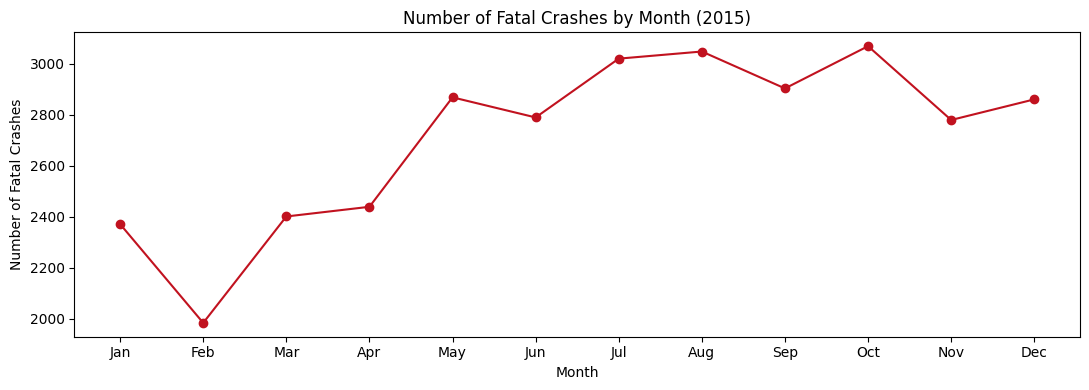

In [30]:
month_nums = list(range(1, 13))

crashes_by_month = crash_df.groupby("crash_month").size().reindex(month_nums, fill_value=0)

crashes_by_month.index = calendar.month_abbr[1:]

print(crashes_by_month)

plt.figure(figsize=(11, 4))

plt.plot(crashes_by_month.index, crashes_by_month.values, marker="o", color="#c1121f")

plt.ylabel("Number of Fatal Crashes")
plt.xlabel("Month")
plt.title("Number of Fatal Crashes by Month (2015)")

plt.tight_layout()
plt.show()

crash_hour
0     1514
1     1227
2     1207
3      946
4      751
5     1000
6     1203
7     1144
8      910
9      959
10    1020
11    1126
12    1222
13    1386
14    1513
15    1684
16    1650
17    1838
18    1894
19    1783
20    1861
21    1810
22    1555
23    1335
dtype: int64


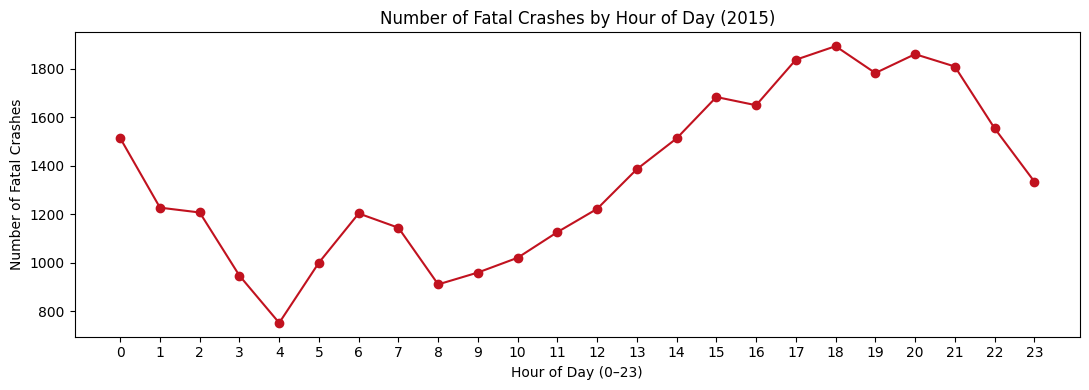

In [31]:
by_hour = crash_df.groupby("crash_hour").size().reindex(range(24), fill_value=0)

print(by_hour)

plt.figure(figsize=(11, 4))

plt.plot(by_hour.index, by_hour.values, marker="o", color="#c1121f")

plt.xticks(range(24))
plt.ylabel("Number of Fatal Crashes")
plt.xlabel("Hour of Day (0–23)")
plt.title("Number of Fatal Crashes by Hour of Day (2015)")

plt.tight_layout()
plt.show()

crash_weekday
Monday       4038
Tuesday      3985
Wednesday    4182
Thursday     4460
Friday       4916
Saturday     5659
Sunday       5298
dtype: int64


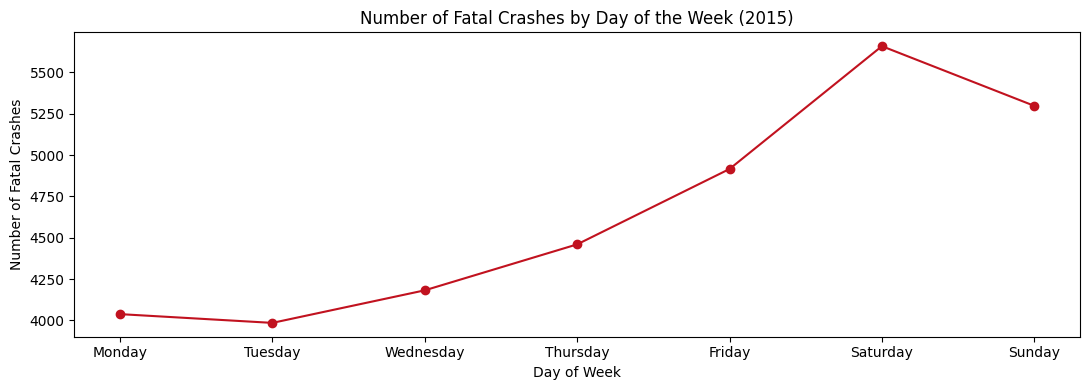

In [32]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = crash_df.groupby("crash_weekday").size().reindex(weekday_order).fillna(0)

print(by_day)

plt.figure(figsize=(11, 4))

plt.plot(by_day.index, by_day.values, marker="o", color="#c1121f")

plt.ylabel("Number of Fatal Crashes")
plt.xlabel("Day of Week")
plt.title("Number of Fatal Crashes by Day of the Week (2015)")

plt.tight_layout()
plt.show()

## 6. Alcohol (drivers)

From here on the analysis is restricted to drivers with a known outcome.

In [33]:
blocks = ["00-03", "04-07", "08-11", "12-15", "16-19", "20-23"]

drivers = df[(df["person_type"] == 1) & df["injury_severity"].isin([0, 1, 2, 3, 4])].copy()
drivers["killed"] = drivers["injury_severity"] == 4
drivers["outcome"] = np.where(drivers["killed"], "Killed", "Survived")
drivers["hour"] = drivers["crash_hour"]
drivers["time_block"] = pd.cut(drivers["hour"], bins=[-1, 3, 7, 11, 15, 19, 23], labels=blocks)
drivers["has_bac"] = (drivers["alcohol_test_status1"] == "Test Given") & drivers["bac"].notna()

print("drivers with known outcome:", len(drivers))
print(drivers["outcome"].value_counts())
print("drivers with a BAC reading:", drivers["has_bac"].sum())

drivers with known outcome: 48429
outcome
Survived    26079
Killed      22350
Name: count, dtype: int64
drivers with a BAC reading: 23842


In [34]:
cov = drivers.groupby("outcome")["has_bac"].agg(drivers="size", with_bac="sum", share="mean")
cov["share"] = (cov["share"] * 100).round(1)
print(cov)

          drivers  with_bac  share
outcome                           
Killed      22350     16430   73.5
Survived    26079      7412   28.4


**Caveat for the alcohol analyses below.** A BAC reading exists only for drivers who were tested, and testing depends on the outcome (73.5% of killed drivers vs 28.4% of survivors). Every share-killed figure, chart and odds ratio in this section describes *tested drivers only*, so it is selection-biased and should not be read as the effect of alcohol on the whole driver population.

            drivers  killed  share_killed
bac_band                                 
0.00          15824   10212          64.5
0.01-0.079     1499    1075          71.7
0.08-0.149     2009    1348          67.1
0.15+          4510    3795          84.1


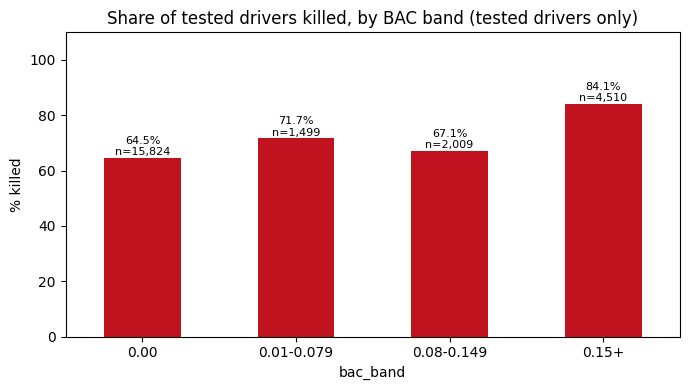

In [35]:
tested_d = drivers[drivers["has_bac"]].copy()
tested_d["over_limit"] = tested_d["bac"] >= 0.08
tested_d["bac_band"] = pd.cut(tested_d["bac"], bins=[-0.001, 0.0, 0.079, 0.149, 0.999],
                              labels=["0.00", "0.01-0.079", "0.08-0.149", "0.15+"])

t = (tested_d.groupby("bac_band", observed=True)["killed"]
             .agg(drivers="size", killed="sum", share_killed="mean"))
t["share_killed"] = (t["share_killed"] * 100).round(1)
print(t)

ax = t["share_killed"].plot(kind="bar", figsize=(7, 4), color="#c1121f")
for i, (s, n) in enumerate(zip(t["share_killed"], t["drivers"])):
    ax.text(i, s + 1, f"{s}%\nn={n:,}", ha="center", fontsize=8)
ax.set_ylabel("% killed")
ax.set_ylim(0, 110)
ax.set_title("Share of tested drivers killed, by BAC band (tested drivers only)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

                     tested  over_limit  share
time_block outcome                            
00-03      Killed      2666        1714   64.3
           Survived    1005         453   45.1
04-07      Killed      2163         531   24.5
           Survived     887         123   13.9
08-11      Killed      2162         168    7.8
           Survived     884          31    3.5
12-15      Killed      3019         356   11.8
           Survived    1359          94    6.9
16-19      Killed      3486         992   28.5
           Survived    1721         257   14.9
20-23      Killed      2934        1382   47.1
           Survived    1556         418   26.9


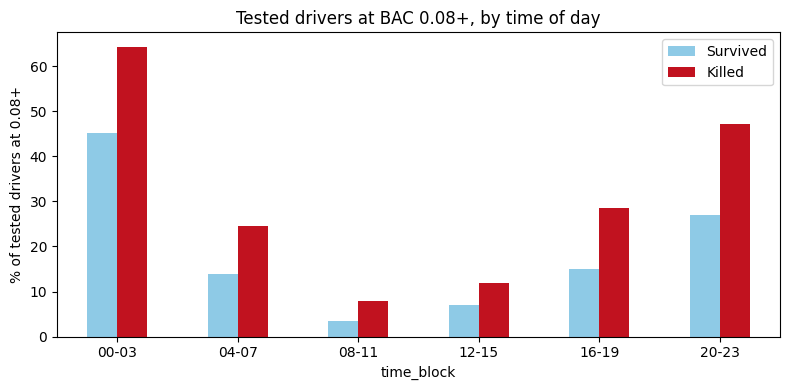

In [36]:
ol = (tested_d.groupby(["time_block", "outcome"], observed=True)["over_limit"]
              .agg(tested="size", over_limit="sum", share="mean"))
ol["share"] = (ol["share"] * 100).round(1)
print(ol)

ol["share"].unstack()[["Survived", "Killed"]].plot(
    kind="bar", figsize=(8, 4), color=["#8ecae6", "#c1121f"])
plt.ylabel("% of tested drivers at 0.08+")
plt.title("Tested drivers at BAC 0.08+, by time of day")
plt.legend(loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

                       drivers  share_killed
time_block over_limit                       
00-03      False          1504          63.3
           True           2167          79.1
04-07      False          2396          68.1
           True            654          81.2
08-11      False          2847          70.0
           True            199          84.4
12-15      False          3928          67.8
           True            450          79.1
16-19      False          3958          63.0
           True           1249          79.4
20-23      False          2690          57.7
           True           1800          76.8


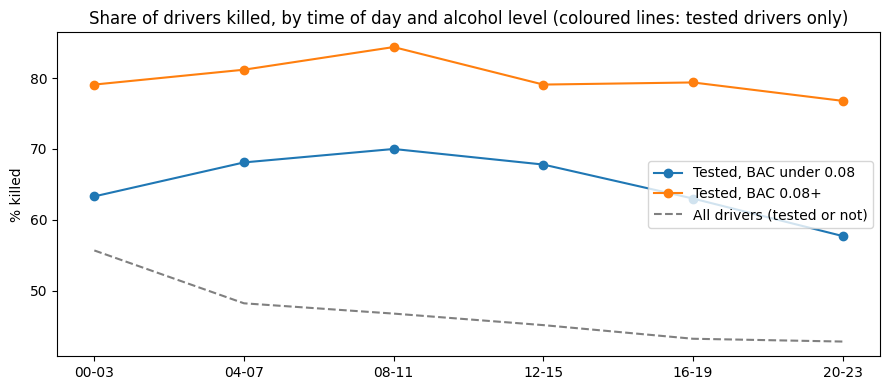

In [37]:
t = (tested_d.groupby(["time_block", "over_limit"], observed=True)["killed"]
             .agg(drivers="size", share_killed="mean"))
t["share_killed"] = (t["share_killed"] * 100).round(1)
print(t)

wide = t["share_killed"].unstack()
all_d = drivers.groupby("time_block", observed=True)["killed"].mean().mul(100)

plt.figure(figsize=(9, 4))
plt.plot(wide.index.astype(str), wide[False], marker="o", label="Tested, BAC under 0.08")
plt.plot(wide.index.astype(str), wide[True], marker="o", label="Tested, BAC 0.08+")
plt.plot(all_d.index.astype(str), all_d.values, linestyle="--", color="grey",
         label="All drivers (tested or not)")
plt.ylabel("% killed")
plt.title("Share of drivers killed, by time of day and alcohol level (coloured lines: tested drivers only)")
plt.legend(loc="center right")
plt.tight_layout()
plt.show()

In [38]:
tested_d["any_alcohol"] = tested_d["bac"] > 0

g = tested_d.groupby("any_alcohol")["killed"].agg(drivers="size", killed="sum", share="mean")
g["share"] = (g["share"] * 100).round(1)
print(g)

ct = pd.crosstab(tested_d["any_alcohol"], tested_d["killed"])
chi2, p, dof, exp = chi2_contingency(ct)
drink_k, drink_s = ct.loc[True, True], ct.loc[True, False]
sober_k, sober_s = ct.loc[False, True], ct.loc[False, False]
odds_ratio = (drink_k / drink_s) / (sober_k / sober_s)
se = np.sqrt(1/drink_k + 1/drink_s + 1/sober_k + 1/sober_s)
lo, hi = np.exp(np.log(odds_ratio) + np.array([-1.96, 1.96]) * se)
print(f"[tested drivers only, selection-biased] chi-square p = {p:.3g}; odds ratio = {odds_ratio:.2f} (95% CI {lo:.2f} to {hi:.2f})")

             drivers  killed  share
any_alcohol                        
False          15824   10212   64.5
True            8018    6218   77.6
[tested drivers only, selection-biased] chi-square p = 2.21e-93; odds ratio = 1.90 (95% CI 1.78 to 2.02)


## 7. Drugs (drivers)

**Caveat.** The same selection problem applies to drug testing: 71.5% of drivers who were tested for drugs were killed, against 27.3% of those not tested. Test status partly reflects the outcome, so the figures below describe tested drivers only.

drug_test_status  Test Given  Test Not Given  Test Refused
outcome                                                   
Killed                 14367            6837             2
Survived                5717           18163            34


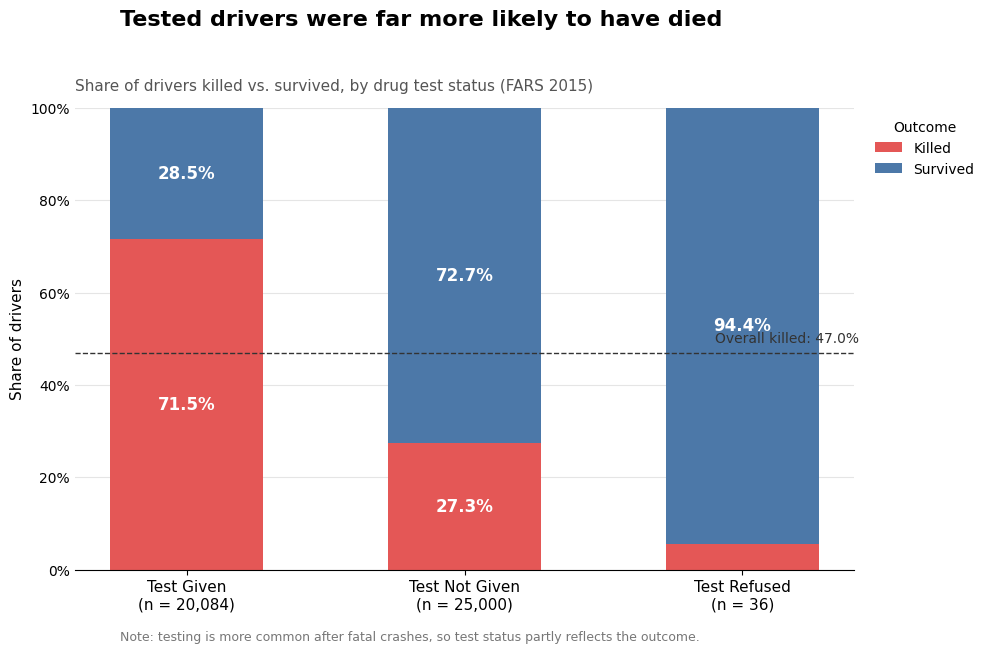

In [39]:
print(pd.crosstab(drivers['outcome'], drivers['drug_test_status']))

# Colours
colors = {'Killed': '#E45756', 'Survived': '#4C78A8'}

# Data
order = ['Test Given', 'Test Not Given', 'Test Refused']
ct = pd.crosstab(drivers['drug_test_status'], drivers['outcome']).loc[order]
ct = ct[['Killed', 'Survived']]
pct = ct.div(ct.sum(axis=1), axis=0) * 100
overall_killed = ct['Killed'].sum() / ct.values.sum() * 100

# Plot
fig, ax = plt.subplots(figsize=(10, 6.5))
bottom = pd.Series(0.0, index=pct.index)

for outcome in pct.columns:
    bars = ax.bar(pct.index, pct[outcome], bottom=bottom,
                  color=colors[outcome], width=0.55, label=outcome)
    for bar, val, b in zip(bars, pct[outcome], bottom):
        if val >= 8:  # skip labels on slivers too small to read
            ax.text(bar.get_x() + bar.get_width() / 2, b + val / 2,
                    f'{val:.1f}%', ha='center', va='center',
                    color='white', fontsize=12, fontweight='bold')
    bottom += pct[outcome]

# Overall killed-rate reference line
ax.axhline(overall_killed, color='#333333', linestyle='--', linewidth=1)
ax.text(2.42, overall_killed + 1.5, f'Overall killed: {overall_killed:.1f}%',
        ha='right', va='bottom', fontsize=10, color='#333333')

# Category labels with group size
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f'{c}\n(n = {ct.loc[c].sum():,})' for c in order], fontsize=11)

# Axes and titles
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Share of drivers', fontsize=11)
ax.set_xlabel('')
ax.yaxis.grid(True, color='#E5E5E5', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0)

fig.suptitle('Tested drivers were far more likely to have died',
             fontsize=16, fontweight='bold', x=0.125, ha='left')
ax.set_title('Share of drivers killed vs. survived, by drug test status (FARS 2015)',
             fontsize=11, color='#555555', loc='left', pad=12)

ax.legend(title='Outcome', frameon=False, loc='upper left',
          bbox_to_anchor=(1.01, 1))

fig.text(0.125, 0.01,
         'Note: testing is more common after fatal crashes, so test status partly reflects the outcome.',
         fontsize=9, color='#777777', ha='left')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [40]:
pd.crosstab(drivers['drug_test_status'], drivers['killed'], normalize='index')

killed,False,True
drug_test_status,,
Test Given,0.284654,0.715346
Test Not Given,0.726520,0.273480
Test Refused,0.944444,0.055556


In [41]:
# 1. Tested drivers only
tested = drivers[drivers['drug_test_status'] == 'Test Given'].copy()
slots = ['drug_test_type4', 'drug_test_type5', 'drug_test_type6']
tested[slots] = tested[slots].apply(pd.to_numeric, errors='coerce')

# 2. Slot code -> category (ranges as listed in fars_code_reference.txt)
def code_to_cat(c):
    if pd.isna(c) or c == 0:  return None            # empty slot
    if c == 1:                return 'Negative'
    if 100 <= c <= 295:       return 'Narcotic'
    if 300 <= c <= 395:       return 'Depressant'
    if 400 <= c <= 495:       return 'Stimulant'
    if 500 <= c <= 595:       return 'Hallucinogen'
    if 600 <= c <= 695:       return 'Cannabinoid'
    if 700 <= c <= 795:       return 'PCP'
    if 800 <= c <= 895:       return 'Steroid'
    if 900 <= c <= 995:       return 'Inhalant'
    if c == 996:              return 'Other drug'
    if c == 998:              return 'Positive, type unknown'
    if c in (95, 997, 999):   return 'Unknown result'
    return None

main = {'Narcotic', 'Depressant', 'Stimulant', 'Cannabinoid'}
rare = {'Hallucinogen', 'PCP', 'Steroid', 'Inhalant', 'Other drug'}

# 3. One result per driver, combining the three slots
def driver_result(row):
    cats = {code_to_cat(c) for c in row[slots]} - {None}
    found = main & cats
    if len(found) >= 2:                    return 'Multiple drug types'
    if len(found) == 1:                    return found.pop()
    if cats & rare:                        return 'Other drug'
    if 'Positive, type unknown' in cats:   return 'Positive, type unknown'
    if 'Negative' in cats:                 return 'Negative'
    return 'Unknown / no result'

tested['drug_result'] = tested.apply(driver_result, axis=1)


tested['drug_result'].value_counts().reset_index()

,drug_result,count
0,Negative,11122
1,Cannabinoid,2198
2,Multiple drug types,1707
3,Unknown / no result,1228
4,Other drug,1041
5,Stimulant,983
6,Depressant,756
7,Narcotic,728
8,"Positive, type unknown",321


In [42]:
pd.crosstab(tested['drug_result'], tested['outcome'])

outcome,Killed,Survived
drug_result,,
Cannabinoid,1592,606
Depressant,628,128
Multiple drug types,1315,392
Narcotic,561,167
Negative,7817,3305
Other drug,860,181
"Positive, type unknown",224,97
Stimulant,805,178
Unknown / no result,565,663


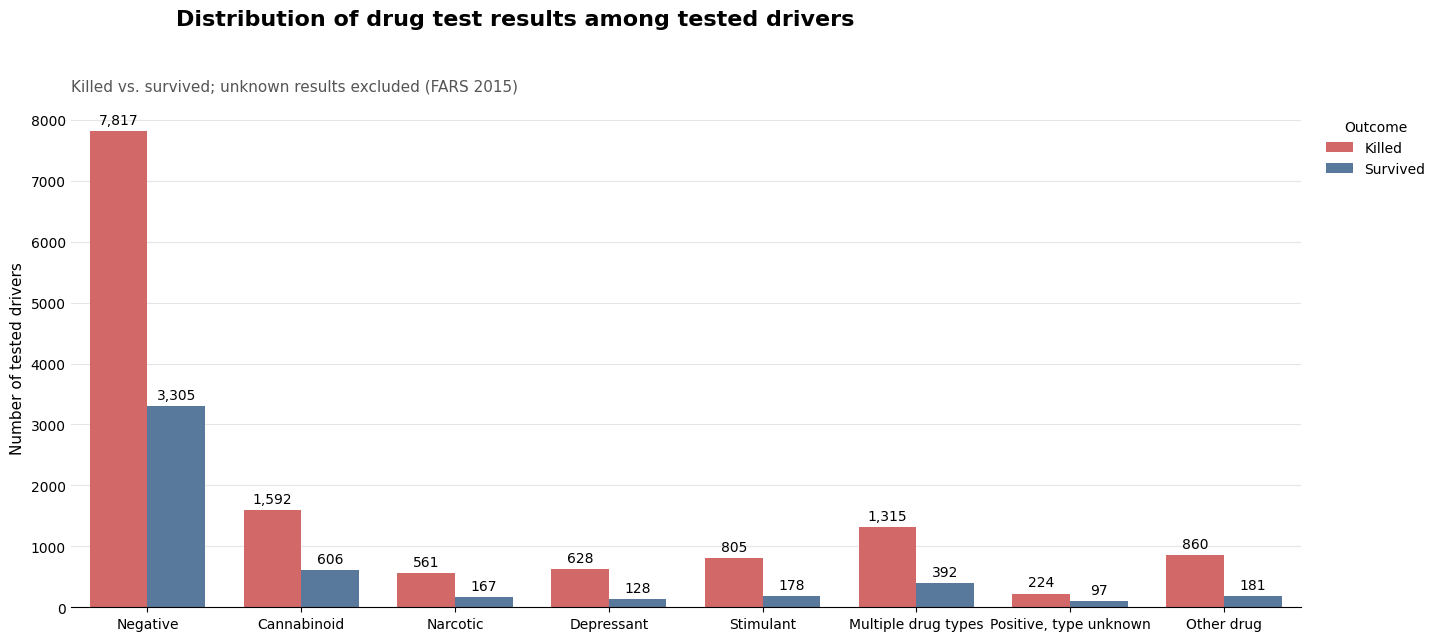

In [43]:
colors = {'Killed': '#E45756', 'Survived': '#4C78A8'}
order = ['Negative', 'Cannabinoid', 'Narcotic', 'Depressant', 'Stimulant',
         'Multiple drug types', 'Positive, type unknown', 'Other drug']

plot_df = tested[tested['drug_result'].isin(order)]
order = [o for o in order if o in plot_df['drug_result'].unique()]

fig, ax = plt.subplots(figsize=(14.5, 6.5))
sns.countplot(data=plot_df, x='drug_result', hue='outcome',
              order=order, hue_order=['Killed', 'Survived'],
              palette=colors, width=0.75, ax=ax)

for c in ax.containers:
    ax.bar_label(c, fmt='{:,.0f}', padding=3, fontsize=10)

ax.set_xlabel('')
ax.set_ylabel('Number of tested drivers', fontsize=11)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, fontsize=10)
ax.yaxis.grid(True, color='#E5E5E5', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0)

fig.suptitle('Distribution of drug test results among tested drivers',
             fontsize=16, fontweight='bold', x=0.125, ha='left')
ax.set_title('Killed vs. survived; unknown results excluded (FARS 2015)',
             fontsize=11, color='#555555', loc='left', pad=12)
ax.legend(title='Outcome', frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1))

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 8. Correlation with driver fatality

Columns are dropped or encoded before the heatmap. Unordered category codes (state, county, make, ...) are left out because a correlation with them is meaningless, and anything built from the outcome is left out so it cannot dominate the chart.

In [44]:
heat = drivers.copy()

drop_cols = [
    # identifiers and raw time
    'consecutive_number', 'person_number', 'timestamp_of_crash', 'hour', 'time_block',

    # category codes with no order (correlation would be meaningless)
    'state_number', 'county', 'vehicle_make', 'body_type',
    'manner_of_collision', 'first_harmful_event', 'first_event_group',

    # the outcome in disguise (would swamp everything else)
    'injury_severity', 'injury_level', 'deaths_in_crash', 'death_per_crash', 'outcome',

    # raw versions already replaced by cleaner columns
    'functional_system', 'ejection',
    'drug_test_type4', 'drug_test_type5', 'drug_test_type6',

    # testing is more common after fatal crashes, so these are biased
    'drug_test_status', 'alcohol_test_status1',

    # same value for every row (drivers only)
    'person_type',
]

heat = heat.drop(columns=drop_cols)
print(heat.shape)

(48429, 22)


In [45]:
for c in heat.select_dtypes(include=['object', 'string']).columns:
    print(f'--- {c}')
    print(heat[c].value_counts(dropna=False).head(6))
    print()

--- school_bus_related
school_bus_related
No     48216
Yes      213
Name: count, dtype: int64

--- rollover
rollover
No Rollover                            40471
Rollover, Tripped by Object/Vehicle     6659
Rollover, Untripped                      981
Rollover, Unknown Type                   318
Name: count, dtype: int64

--- fire_occurrence
fire_occurrence
No or Not Reported    46852
Yes                    1577
Name: count, dtype: int64

--- sex
sex
Male      35661
Female    12304
<NA>        464
Name: count, dtype: int64

--- police_reported_alcohol_involvement
police_reported_alcohol_involvement
No (Alcohol Not Involved)    28695
<NA>                         13197
Yes (Alcohol Involved)        6537
Name: count, dtype: int64

--- police_reported_drug_involvement
police_reported_drug_involvement
No (Drugs Not Involved)    27505
<NA>                       17829
Yes (Drugs Involved)        3095
Name: count, dtype: int64

--- crash_weekday
crash_weekday
Saturday     8120
Friday       750

In [46]:
heat_enc = pd.DataFrame(index=heat.index)

# Outcome
heat_enc['killed'] = heat['killed'].astype(int)

# Numeric columns, kept as they are
heat_enc['age'] = heat['age'].astype(float).where(lambda s: s <= 120)
heat_enc['vehicles_involved'] = heat['number_of_motor_vehicles_in_transport_mvit'].astype(float)
heat_enc['people_in_crash'] = heat['people_in_crash'].astype(float)
heat_enc['bac'] = heat['bac']
heat_enc['any_drug_found'] = heat['any_drug_found']
heat_enc['is_weekend'] = heat['is_weekend'].astype(int)

# Yes/No text columns
heat_enc['school_bus'] = heat['school_bus_related'].map({'Yes': 1, 'No': 0})
heat_enc['fire'] = heat['fire_occurrence'].map({'Yes': 1, 'No or Not Reported': 0})
heat_enc['rollover_any'] = heat['rollover'].map({
    'No Rollover': 0,
    'Rollover, Tripped by Object/Vehicle': 1,
    'Rollover, Untripped': 1,
    'Rollover, Unknown Type': 1})
heat_enc['male'] = heat['sex'].map({'Male': 1, 'Female': 0})
heat_enc['alcohol_police'] = heat['police_reported_alcohol_involvement'].map(
    {'Yes (Alcohol Involved)': 1, 'No (Alcohol Not Involved)': 0})
heat_enc['drugs_police'] = heat['police_reported_drug_involvement'].map(
    {'Yes (Drugs Involved)': 1, 'No (Drugs Not Involved)': 0})

# Coded columns (see fars_code_reference.txt)
heat_enc['urban'] = heat['land_use'].astype(float).map({1: 0, 2: 1})

r = heat['restraint_system_helmet_use'].astype(float)
heat_enc['restrained'] = np.where(r.isin([1, 2, 3, 4, 5, 8, 10, 11, 12, 16, 19]), 1,
                          np.where(r.isin([7, 17]), 0, np.nan))

a = heat['air_bag_deployed'].astype(float)
heat_enc['airbag_deployed'] = np.where(a.isin([1, 2, 3, 7, 8, 9]), 1,
                              np.where(a.isin([20, 28]), 0, np.nan))

# Time of day: night = 22:00 to 05:59
h = heat['crash_hour']
heat_enc['night'] = ((h >= 22) | (h <= 5)).astype(int)

# Ordered columns
def eject_code(x):
    if pd.isna(x): return np.nan
    x = str(x).lower()
    if x.startswith('not ejected'): return 0
    if 'unknown degree' in x:       return 1.5   # ejected, degree unknown: between partial and total
    if 'partial' in x:              return 1
    if 'total' in x:                return 2
    return np.nan

heat_enc['ejection'] = heat['ejection_level'].astype(object).map(eject_code)
heat_enc['road_type_ord'] = pd.to_numeric(heat['functional_system_ord'].astype('string'),
                                          errors='coerce')

print(heat_enc.shape)
print(heat_enc.notna().sum())          # how many drivers each column covers

(48429, 19)
killed               48429
age                  47939
vehicles_involved    48429
people_in_crash      48429
bac                  23842
any_drug_found       18856
is_weekend           48429
school_bus           48429
fire                 48429
rollover_any         48429
male                 47965
alcohol_police       35232
drugs_police         30600
urban                48171
restrained           44514
airbag_deployed      36830
night                48429
ejection             43152
road_type_ord        48073
dtype: int64


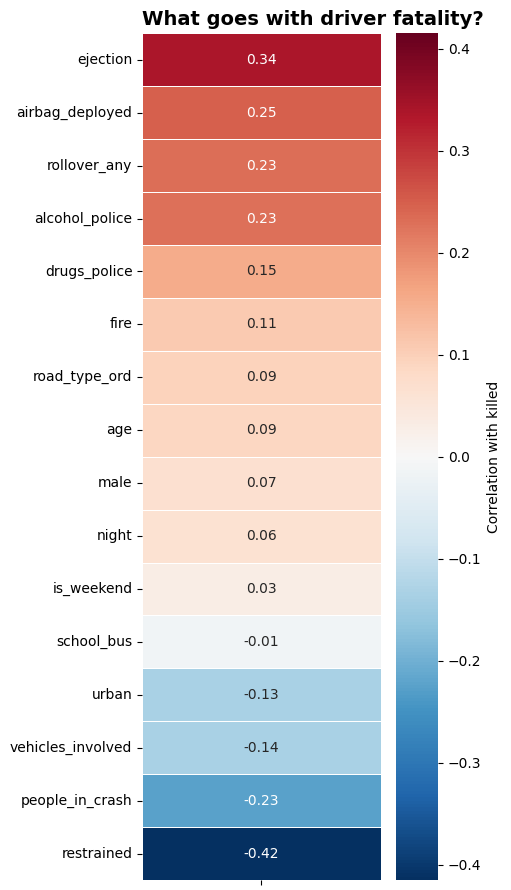

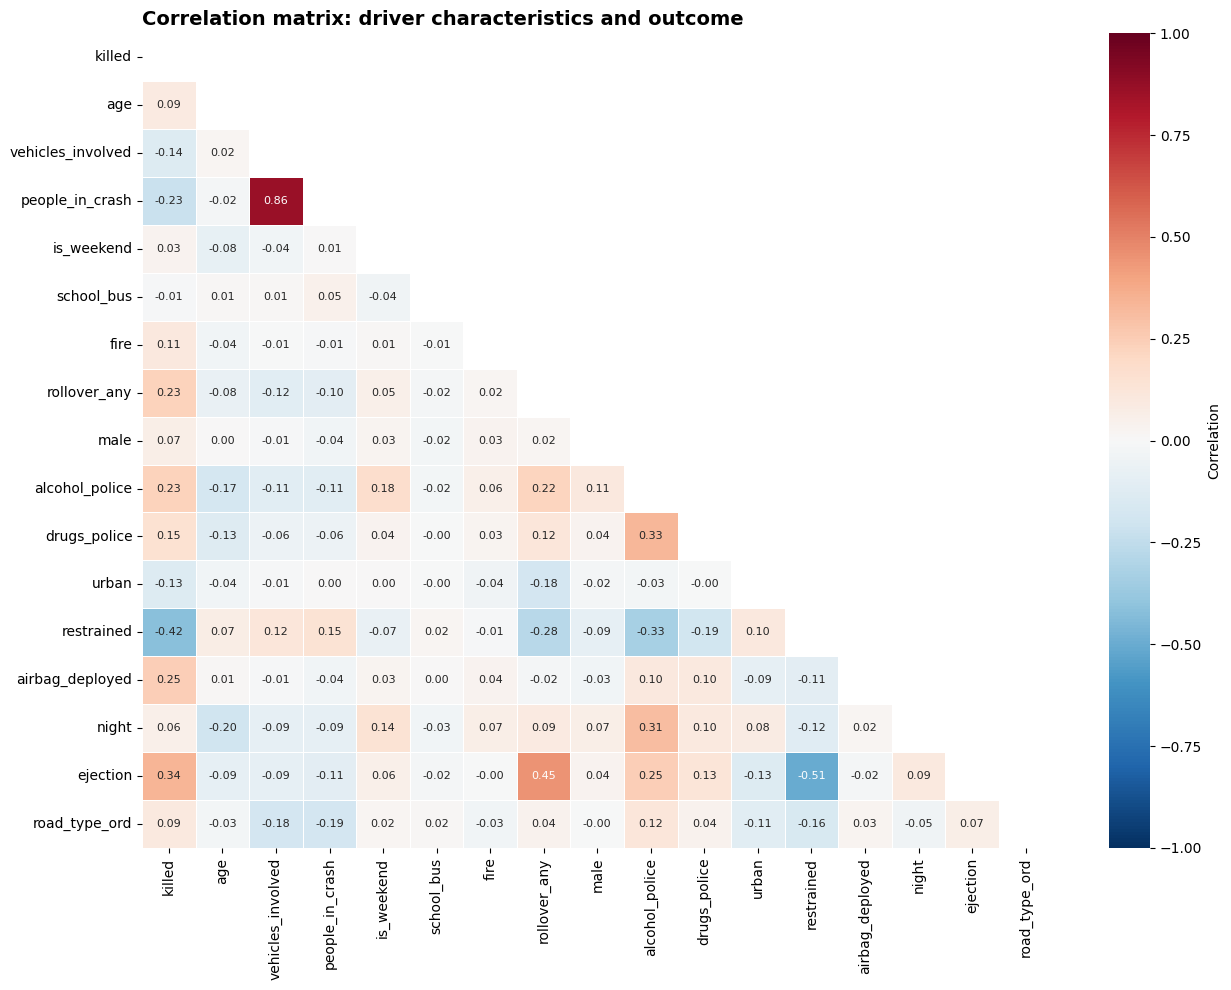

In [47]:
# bac and any_drug_found are left out: they only exist for tested drivers, and testing depends on the outcome
corr = heat_enc.drop(columns=['bac', 'any_drug_found']).corr()
target = corr['killed'].drop('killed').sort_values(ascending=False)
lim = max(abs(target.min()), abs(target.max()))

# Chart 1: correlation of each variable with "killed"
fig, ax = plt.subplots(figsize=(5, 9))
sns.heatmap(target.to_frame('killed'), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-lim, vmax=lim, linewidths=0.5,
            cbar_kws={'label': 'Correlation with killed'}, ax=ax)
ax.set_title('What goes with driver fatality?', loc='left', fontsize=14, fontweight='bold')
ax.set_ylabel('')
ax.set_xticklabels([''])
plt.tight_layout()
plt.show()

# Chart 2: full matrix, lower triangle only
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', annot_kws={'size': 8},
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={'label': 'Correlation'}, ax=ax)
ax.set_title('Correlation matrix: driver characteristics and outcome',
             loc='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Vehicle class and restraint / helmet use

`body_class` groups FARS body-type codes into eight vehicle classes. The restraint analysis then compares drivers who were restrained (belt, child seat or helmet), not restrained, and unknown, using the same grouping as the `restrained` model feature.

In [48]:
def body_class(c):
    if pd.isna(c):
        return "Unknown"
    c = int(c)
    if 1 <= c <= 13:   return "Car"
    if 14 <= c <= 19:  return "SUV"
    if 20 <= c <= 29:  return "Van"
    if 30 <= c <= 39:  return "Pickup"
    if 50 <= c <= 59:  return "Bus"
    if 60 <= c <= 79:  return "Heavy truck"
    if 80 <= c <= 89:  return "Motorcycle/moped"
    return "Other/unknown"
mdl = drivers.copy()
mdl["vehicle_class"] = mdl["body_type"].map(body_class)
 
chk = (mdl.groupby("vehicle_class")["killed"]
          .agg(drivers="size", share_killed="mean").round(3)
          .sort_values("drivers", ascending=False))
print(chk)

                  drivers  share_killed
vehicle_class                          
Car                 19514         0.479
Pickup               8678         0.406
SUV                  7619         0.389
Motorcycle/moped     5121         0.925
Heavy truck          4031          0.15
Van                  2149         0.322
Other/unknown        1058         0.454
Bus                   259         0.062


### Restraint and helmet use

Three questions: how many drivers fall in each group, how many are killed, and whether "unknown" behaves differently for killed and surviving drivers (the problem that rules out BAC as a feature). The last chart separates motorcycle and moped riders, whose restraint is a helmet, from everyone else, whose restraint is a belt or child seat.

                 drivers  share_killed  share_of_drivers_%
restraint_group                                           
Not restrained     11776         0.811              24.316
Restrained         32738         0.341                67.6
Unknown             3915         0.417               8.084 

      drivers  share_killed
code                       
-1       3877         0.414
1         137         0.409
2         254         0.398
3       28630         0.277
5        1223         0.928
7        9551         0.787
8         634         0.347
16        149         0.926
17       2225         0.911
19       1711         0.934
97         38         0.763 

restraint_group  Not restrained  Restrained  Unknown
killed                                              
False                       8.6        82.7      8.7
True                       42.7        50.0      7.3 



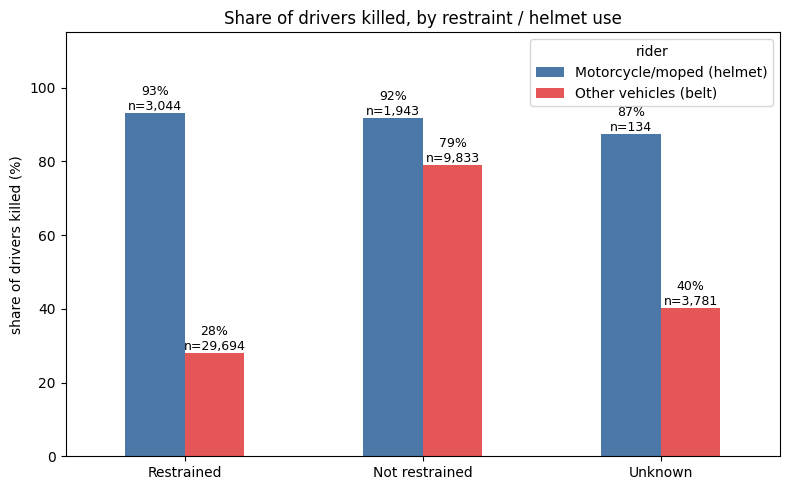

In [49]:
# ---- Restraint / helmet use among drivers ----
r = mdl["restraint_system_helmet_use"]
mdl["restraint_group"] = np.select(
    [r.isin([1, 2, 3, 4, 5, 8, 10, 11, 12, 16, 19]), r.isin([7, 17])],
    ["Restrained", "Not restrained"], default="Unknown")      # same grouping as the model's `restrained` feature

# 1) overall
overall = mdl.groupby("restraint_group")["killed"].agg(drivers="size", share_killed="mean")
overall["share_of_drivers_%"] = overall["drivers"] / overall["drivers"].sum() * 100
print(overall.round(3), "\n")

# 2) raw codes (-1 = set to missing earlier: 0, 29, 98, 99), to check against fars_code_reference.txt
print(mdl.groupby(r.fillna(-1).rename("code"))["killed"].agg(drivers="size", share_killed="mean").round(3), "\n")

# 3) is "unknown" more common for killed or surviving drivers? (row % per outcome)
print(pd.crosstab(mdl["killed"], mdl["restraint_group"], normalize="index").mul(100).round(1), "\n")

# 4) share killed by restraint: helmets (motorcycles) vs belts / child seats (everything else)
mdl["rider"] = np.where(mdl["vehicle_class"] == "Motorcycle/moped", "Motorcycle/moped (helmet)", "Other vehicles (belt)")
g = mdl.groupby(["restraint_group", "rider"])["killed"].agg(["mean", "size"]).unstack("rider")
order = ["Restrained", "Not restrained", "Unknown"]
share, n = g["mean"].reindex(order) * 100, g["size"].reindex(order)

ax = share.plot.bar(rot=0, figsize=(8, 5), color=["#4C78A8", "#E45756"])
for cont, col in zip(ax.containers, share.columns):
    ax.bar_label(cont, labels=[f"{v:.0f}%\nn={int(k):,}" if pd.notna(v) else "" for v, k in zip(share[col], n[col].fillna(0))], fontsize=9)
ax.set_ylim(0, 115); ax.set_xlabel(""); ax.set_ylabel("share of drivers killed (%)")
ax.set_title("Share of drivers killed, by restraint / helmet use")
plt.tight_layout(); plt.show()

**Reading the restraint results** (drivers with a known outcome, n = 48,429)

| Group | Drivers | Share of drivers | Share killed |
|---|---:|---:|---:|
| Restrained | 32,738 | 67.6% | 34.1% |
| Not restrained | 11,776 | 24.3% | 81.1% |
| Unknown | 3,915 | 8.1% | 41.7% |

- **"Unknown" is not outcome-driven the way BAC is.** It makes up 8.7% of surviving and 7.3% of killed drivers, so it is kept as a missing value rather than excluded.
- **Cars, SUVs, vans, pickups and trucks:** 28% of belted drivers were killed against 79% of unbelted drivers.
- **Motorcycles and mopeds:** 93% of helmeted and 92% of unhelmeted riders were killed. By raw code, DOT-compliant helmet 92.8% (n = 1,223) against no helmet 91.1% (n = 2,225).
- **The motorcycle result is a property of the data, not evidence that helmets do not work.** FARS only contains crashes in which someone died, and in a single-vehicle motorcycle crash the rider is usually that person. Nearly every rider in the file is therefore killed whatever they wore.
- The comparisons are associations among people already in fatal crashes. They do not estimate how much a belt or helmet reduces risk in crashes in general.

## 10. Model building

Logistic regression, decision tree, random forest and XGBoost for driver fatality (`killed`).

- Drivers from the same crash always land on the same side of the split, so the test set contains only crashes the models have never seen.
- Every model is a pipeline: median imputation with missing-value flags (plus scaling for logistic regression). Each pickle is therefore usable on its own.

### Features

In [50]:
# Left out of the features:
#  - bac, any_drug_found: only recorded for tested drivers, and killed drivers were tested far more often,
#    so "has a value" would leak the outcome
#  - people_in_crash: a crash-level count, also used to build death_per_crash
drop_features = ["bac", "any_drug_found", "people_in_crash"]

X = heat_enc.drop(columns=["killed"] + drop_features)
# vehicle class as dummies; Car is the reference group (its dummy is dropped, so no collinearity)
X = X.join(pd.get_dummies(mdl["vehicle_class"], prefix="veh", dtype=int).drop(columns="veh_Car"))
y = heat_enc["killed"]
vehicle_cols = [c for c in X.columns if c.startswith("veh_")]
groups = drivers.loc[X.index, "consecutive_number"]      # crash id: drivers from one crash stay together
X.shape

(48429, 22)

### Is missingness related to the outcome?
Same check as for BAC, now for every feature with gaps.

In [51]:
miss = X.isna().groupby(y).mean().T * 100
miss.columns = ["survived_%", "killed_%"]
miss["gap_pts"] = miss["killed_%"] - miss["survived_%"]
miss = miss[(miss[["survived_%", "killed_%"]] > 0).any(axis=1)]
miss.round(1).sort_values("gap_pts", key=abs, ascending=False)

,survived_%,killed_%,gap_pts
ejection,1.9,21.4,19.5
airbag_deployed,16.3,32.9,16.7
alcohol_police,19.9,35.8,15.9
drugs_police,30.2,44.6,14.4
age,1.8,0.0,-1.8
male,1.8,0.0,-1.7
restrained,8.7,7.3,-1.4
road_type_ord,0.7,0.8,0.1
urban,0.5,0.5,-0.0


**Reading the table.** The `ejection` gap (19.5 points) matches the share of killed drivers on motorcycles (about 21%), for whom ejection is not applicable, and `airbag_deployed` is largely missing for motorcycles too, so these two gaps are mostly structural.

`alcohol_police` and `drugs_police` are also missing more often for killed drivers (15.9 and 14.4 points), and vehicle type does not explain that. All four features stay in the model. Missing values are imputed with the median and each gap also gets a missing-value flag, so "unknown" is not silently turned into "no", but the flag can carry some outcome information. The importance of these four features should be read with that in mind.

### Train/test split by crash

In [52]:
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups))
X_train, X_test = X.iloc[tr], X.iloc[te]
y_train, y_test = y.iloc[tr], y.iloc[te]
g_train = groups.iloc[tr]

print(X_train.shape, X_test.shape, f"| killed share  train {y_train.mean():.3f}  test {y_test.mean():.3f}")
overlap = len(set(groups.iloc[tr]) & set(groups.iloc[te]))
print("crashes present in both train and test:", overlap)
assert overlap == 0

(38720, 22) (9709, 22) | killed share  train 0.462  test 0.460
crashes present in both train and test: 0


### Baseline models (default settings)
A `Train AUC` far above `ROC AUC` means overfitting.

In [53]:
def make_model(clf, scale=False):
    steps = [("imp", SimpleImputer(strategy="median", add_indicator=True).set_output(transform="pandas"))]
    if scale:
        steps.append(("scale", StandardScaler().set_output(transform="pandas")))
    return Pipeline(steps + [("clf", clf)])

models = {
    "Logistic Regression": make_model(LogisticRegression(max_iter=1000), scale=True),
    "Decision Tree": make_model(DecisionTreeClassifier(random_state=42)),
    "Random Forest": make_model(RandomForestClassifier(random_state=42, n_jobs=-1)),
    "XGBoost": make_model(XGBClassifier(eval_metric="logloss", random_state=42)),
}

def evaluate(models):
    rows = {}
    for name, m in models.items():
        pred, prob = m.predict(X_test), m.predict_proba(X_test)[:, 1]
        rows[name] = {"Accuracy": accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred),
                      "Recall": recall_score(y_test, pred),
                      "F1": f1_score(y_test, pred),
                      "ROC AUC": roc_auc_score(y_test, prob),
                      "Train AUC": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])}
    return pd.DataFrame(rows).T.round(3)

for m in models.values():
    m.fit(X_train, y_train)
results_base = evaluate(models)
results_base

,Accuracy,Precision,Recall,F1,ROC AUC,Train AUC
Logistic Regression,0.804,0.816,0.743,0.778,0.884,0.882
Decision Tree,0.735,0.714,0.709,0.711,0.737,1.000
Random Forest,0.793,0.778,0.771,0.774,0.873,0.999
XGBoost,0.817,0.816,0.778,0.797,0.897,0.927


### Hyperparameter tuning
`RandomizedSearchCV` (`N_ITER` random combinations, 3-fold CV grouped by crash, scored on ROC AUC) runs on the training set only; the test set stays untouched. `models` then holds the tuned versions and every plot below uses them. The grids are wide, so this cell takes a while.

In [54]:
N_ITER = 30
grids = {
    "Logistic Regression": {"clf__C": loguniform(1e-3, 1e2)},
    "Decision Tree": {"clf__max_depth": range(3, 31), "clf__min_samples_leaf": [5, 10, 25, 50, 100, 200],
                      "clf__criterion": ["gini", "entropy"]},
    "Random Forest": {"clf__n_estimators": [200, 300, 500, 800], "clf__max_depth": [8, 12, 16, 24, None],
                      "clf__min_samples_leaf": [1, 2, 3, 5, 10], "clf__max_features": ["sqrt", 0.3, 0.5]},
    "XGBoost": {"clf__n_estimators": [200, 400, 600, 800], "clf__max_depth": [3, 4, 5, 6, 8, 10],
                "clf__learning_rate": [0.01, 0.02, 0.05, 0.1], "clf__subsample": [0.7, 0.85, 1.0],
                "clf__colsample_bytree": [0.5, 0.7, 0.85, 1.0], "clf__min_child_weight": [1, 3, 5, 10]},
}

baseline_models, tuned = models, {}
# Random Forest and XGBoost already use every CPU core themselves, so their searches run in the main
# process (n_jobs=1). Sending XGBoost to extra worker processes crashed on Windows.
search_jobs = {"Logistic Regression": -1, "Decision Tree": -1, "Random Forest": 1, "XGBoost": 1}
for name, m in baseline_models.items():
    search = RandomizedSearchCV(m, grids[name], n_iter=N_ITER, cv=GroupKFold(n_splits=3),
                                scoring="roc_auc", n_jobs=search_jobs[name], random_state=42)
    search.fit(X_train, y_train, groups=g_train)
    tuned[name] = search.best_estimator_
    print(f"{name}: CV AUC {search.best_score_:.3f} | {search.best_params_}")

models = tuned
results_tuned = evaluate(models)
results_compare = (pd.concat({"Baseline": results_base, "Tuned": results_tuned},
                             names=["Version", "Model"])
                   .swaplevel().sort_index())
results_compare

Logistic Regression: CV AUC 0.882 | {'clf__C': np.float64(0.033205591037519584)}
Decision Tree: CV AUC 0.881 | {'clf__min_samples_leaf': 50, 'clf__max_depth': 17, 'clf__criterion': 'entropy'}
Random Forest: CV AUC 0.895 | {'clf__n_estimators': 200, 'clf__min_samples_leaf': 5, 'clf__max_features': 0.3, 'clf__max_depth': 16}
XGBoost: CV AUC 0.899 | {'clf__subsample': 0.85, 'clf__n_estimators': 800, 'clf__min_child_weight': 5, 'clf__max_depth': 6, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.5}


Accuracy  Precision  Recall     F1  ROC AUC  \
Model               Version                                                 
Decision Tree       Baseline     0.735      0.714   0.709  0.711    0.737   
                    Tuned        0.801      0.799   0.758  0.778    0.882   
Logistic Regression Baseline     0.804      0.816   0.743  0.778    0.884   
                    Tuned        0.804      0.815   0.743  0.777    0.884   
Random Forest       Baseline     0.793      0.778   0.771  0.774    0.873   
                    Tuned        0.814      0.817   0.768  0.792    0.896   
XGBoost             Baseline     0.817      0.816   0.778  0.797    0.897   
                    Tuned        0.820      0.823   0.776  0.799    0.900   

                              Train AUC  
Model               Version              
Decision Tree       Baseline      1.000  
                    Tuned         0.899  
Logistic Regression Baseline      0.882  
                    Tuned         0.882  
Random Forest       Baseline      0.999  
                    Tuned         0.926  
XGBoost             Baseline      0.927  
                    Tuned         0.912

### Confusion matrices (tuned models)

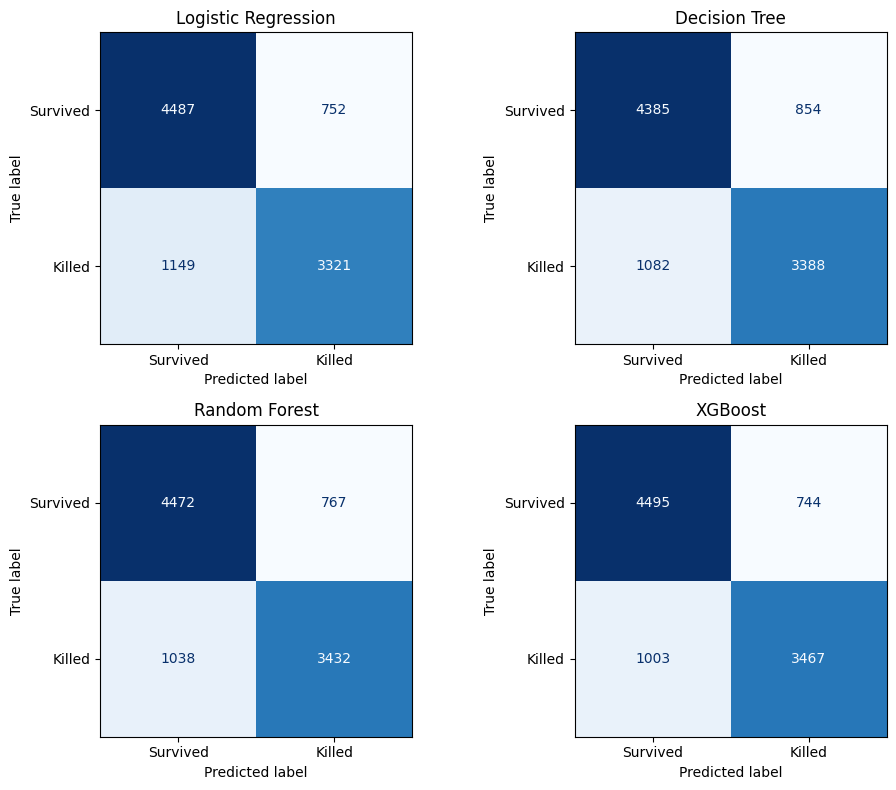

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, m) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["Survived", "Killed"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### ROC and precision-recall curves

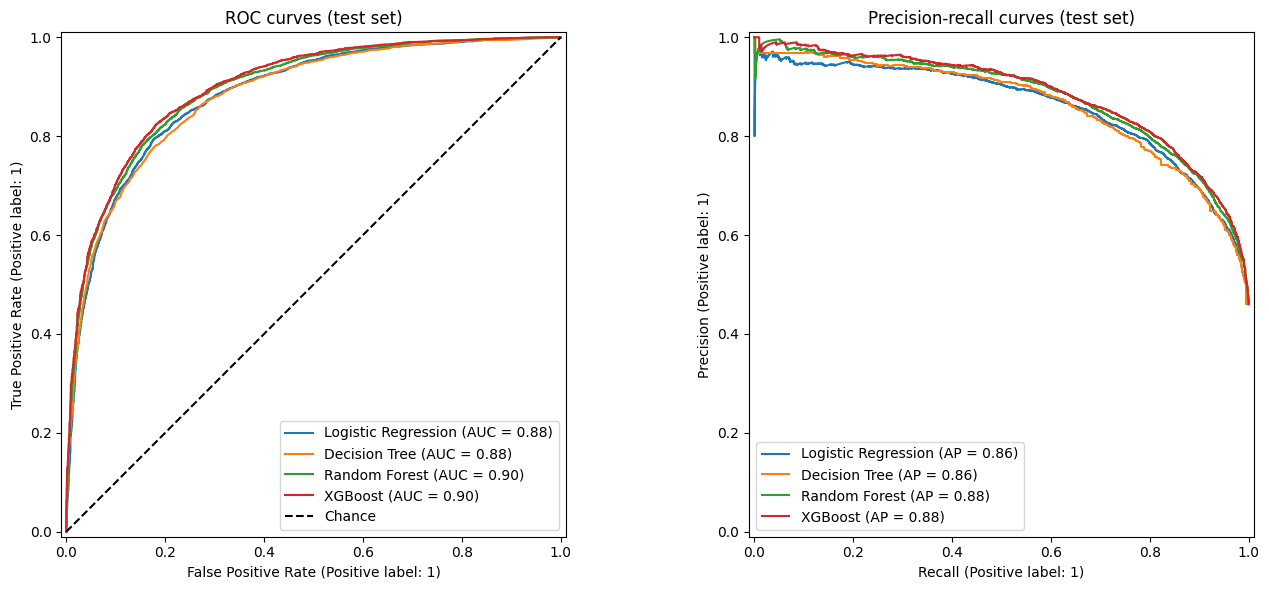

In [56]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax1)
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax2)
ax1.plot([0, 1], [0, 1], "k--", label="Chance")
ax1.legend(); ax1.set_title("ROC curves (test set)")
ax2.set_title("Precision-recall curves (test set)")
plt.tight_layout()
plt.show()

### Feature importance
Permutation importance on the test set: how much ROC AUC drops when a feature is shuffled. This is on the same scale for all four models, and the vehicle-class dummies are shuffled together so vehicle class is measured as one feature.

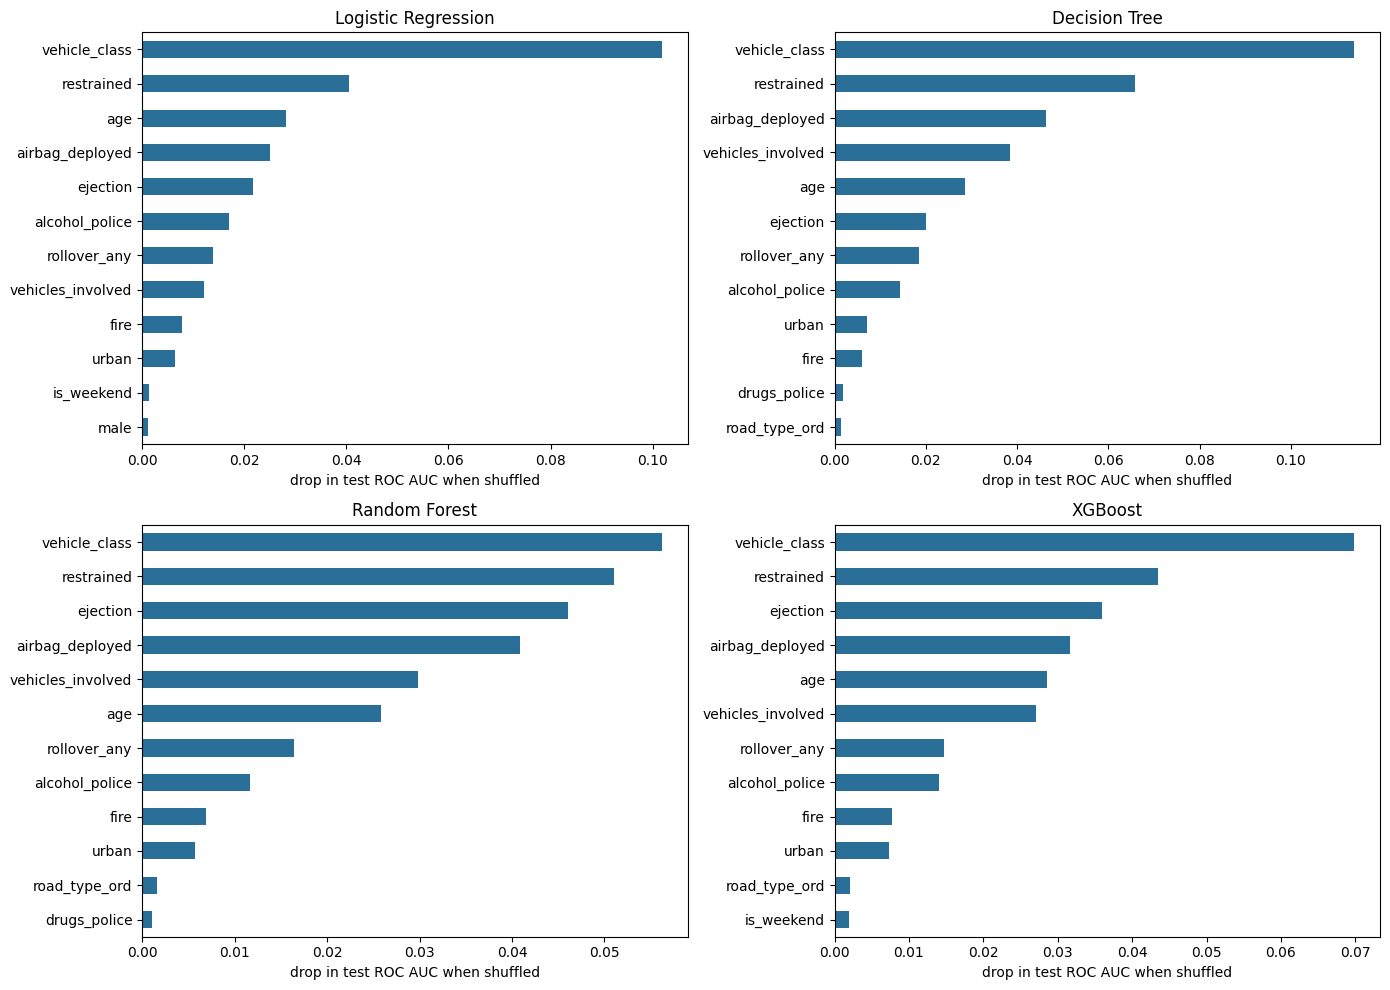

In [57]:
feature_groups = {c: [c] for c in X.columns if c not in vehicle_cols}
feature_groups["vehicle_class"] = vehicle_cols
rng = np.random.default_rng(42)

def perm_importance(model, n_repeats=5):
    base = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    drops = {}
    for feat, cols in feature_groups.items():
        d = []
        for _ in range(n_repeats):
            Xp = X_test.copy()
            Xp[cols] = X_test[cols].iloc[rng.permutation(len(X_test))].to_numpy()
            d.append(base - roc_auc_score(y_test, model.predict_proba(Xp)[:, 1]))
        drops[feat] = np.mean(d)
    return pd.Series(drops)

importances = {name: perm_importance(m) for name, m in models.items()}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, s) in zip(axes.ravel(), importances.items()):
    s.sort_values().tail(12).plot.barh(ax=ax, color="#2a6f97")
    ax.set_title(name)
    ax.set_xlabel("drop in test ROC AUC when shuffled")
plt.tight_layout()
plt.show()

Direction of the effects (logistic regression only). Coefficients are per one standard deviation; vehicle classes are compared with Car.

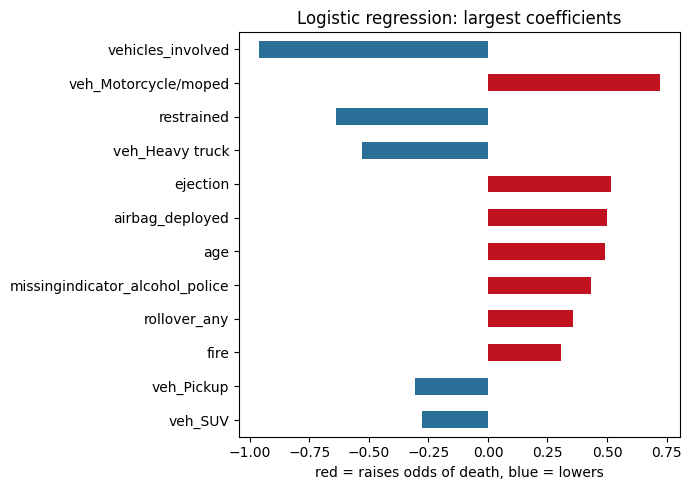

In [58]:
lr = models["Logistic Regression"]
coef = pd.Series(lr["clf"].coef_[0], index=lr[:-1].get_feature_names_out())
top = coef.reindex(coef.abs().sort_values().index).tail(12)
top.plot.barh(figsize=(7, 5), color=np.where(top > 0, "#c1121f", "#2a6f97"))
plt.title("Logistic regression: largest coefficients")
plt.xlabel("red = raises odds of death, blue = lowers")
plt.tight_layout()
plt.show()

### Decision tree structure and model comparison

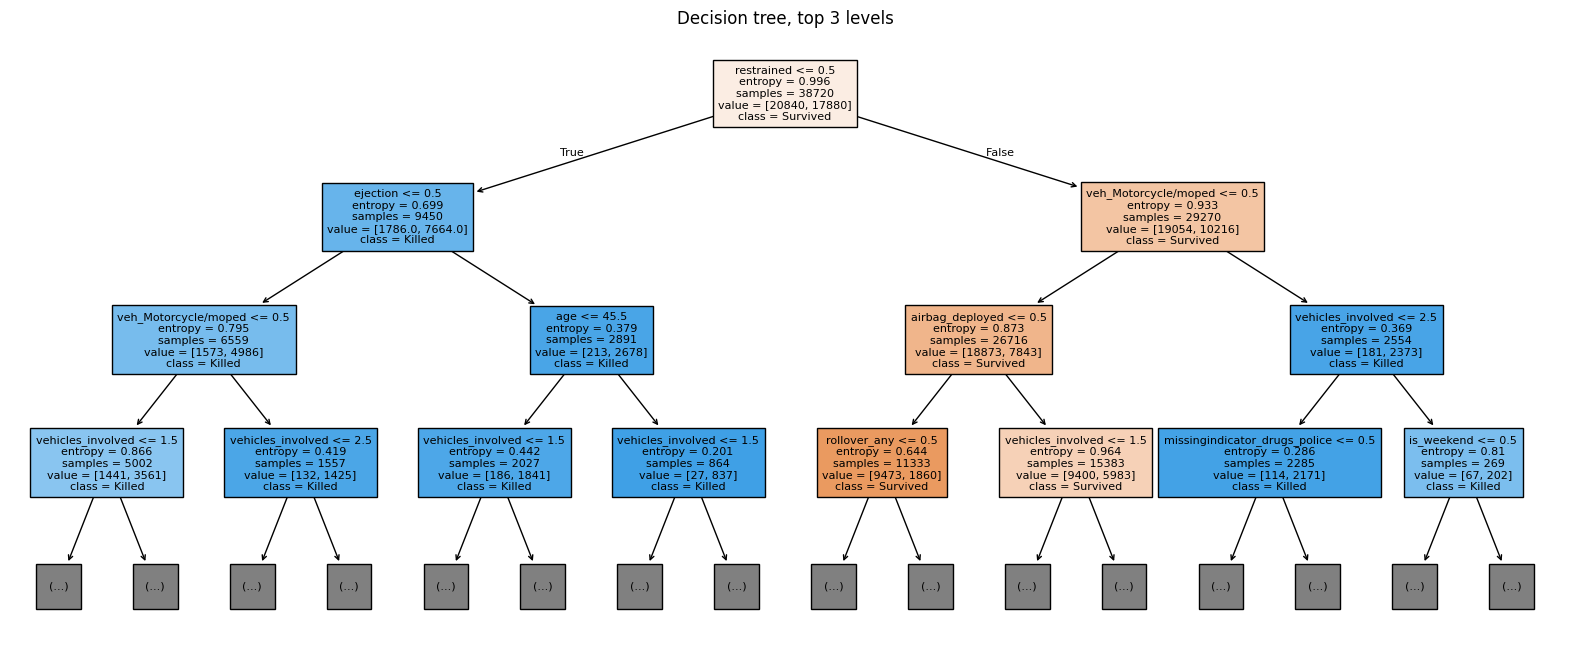

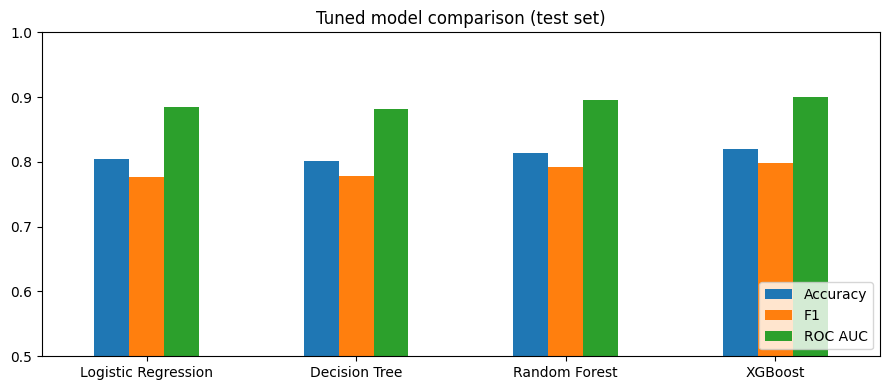

In [59]:
dt = models["Decision Tree"]
plt.figure(figsize=(20, 8))
plot_tree(dt["clf"], max_depth=3, feature_names=list(dt[:-1].get_feature_names_out()),
          class_names=["Survived", "Killed"], filled=True, fontsize=8)
plt.title("Decision tree, top 3 levels")
plt.show()

results_tuned[["Accuracy", "F1", "ROC AUC"]].plot.bar(figsize=(9, 4), rot=0)
plt.ylim(0.5, 1); plt.title("Tuned model comparison (test set)"); plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Sensitivity check: do the outcome-linked features matter?
`alcohol_police` and `drugs_police` are missing more often for killed drivers, and `ejection` and `airbag_deployed` are largely missing for motorcycles (see the missingness table above). This check retrains each tuned model, with its tuned hyperparameters, without those features and compares test ROC AUC. A small change means the headline results do not depend on them.

In [60]:
from sklearn.base import clone

variants = {
    "All features": [],
    "No police-reported alcohol/drugs": ["alcohol_police", "drugs_police"],
    "No police-reported, ejection or airbag": ["alcohol_police", "drugs_police", "ejection", "airbag_deployed"],
}

rows = []
for variant, dropped in variants.items():
    cols = [c for c in X.columns if c not in dropped]
    for name, m in models.items():
        refit = clone(m).fit(X_train[cols], y_train)       # same tuned settings, fewer columns
        prob = refit.predict_proba(X_test[cols])[:, 1]
        rows.append({"Variant": variant, "Model": name, "ROC AUC": roc_auc_score(y_test, prob)})

ablation = (pd.DataFrame(rows).pivot(index="Model", columns="Variant", values="ROC AUC")
              [list(variants)].round(3))
for v in list(variants)[1:]:
    ablation[f"change: {v}"] = (ablation[v] - ablation["All features"]).round(3)
ablation

Variant,All features,No police-reported alcohol/drugs,"No police-reported, ejection or airbag",change: No police-reported alcohol/drugs,"change: No police-reported, ejection or airbag"
Model,,,,,
Decision Tree,0.882,0.877,0.856,-0.005,-0.026
Logistic Regression,0.884,0.877,0.856,-0.007,-0.028
Random Forest,0.896,0.891,0.868,-0.005,-0.028
XGBoost,0.900,0.894,0.872,-0.006,-0.028


### Save models with pickle
Each file is a full pipeline (imputer, scaler where needed, model), so it takes the feature table directly.

In [61]:
os.makedirs("models", exist_ok=True)
for name, m in models.items():
    with open(f"models/{name.lower().replace(' ', '_')}.pkl", "wb") as f:
        pickle.dump(m, f)
with open("models/feature_columns.pkl", "wb") as f:      # exact columns and order the models expect
    pickle.dump(list(X.columns), f)

# reload check: predictions must be identical
with open("models/xgboost.pkl", "rb") as f:
    xgb_loaded = pickle.load(f)
print("reload OK:", np.allclose(xgb_loaded.predict_proba(X_test), models["XGBoost"].predict_proba(X_test)))

reload OK: True


**Using the saved models on new drivers:** encode them exactly like `heat_enc` (same mappings, `body_class`, same dropped columns), build the vehicle dummies with `.reindex(columns=<the veh_ names in feature_columns>, fill_value=0)` so a class missing from the new data still gets a 0 column, then select `new_X[feature_columns]` and call `predict_proba`. Missing values are allowed; the pipeline imputes them.